# Arroyo Capital: inversion en cine

Ethan Schcolnik y Nicolas Gomez

# Etapa 1: limpieza de los datos


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display

# Carpeta con los datos del proyecto
raiz = Path.cwd()
if not (raiz / 'datos' / 'peliculas.csv').exists():
    raiz = raiz.parent
RUTA_DATOS = raiz / 'datos'

# Tipos esperados para las columnas de peliculas
tipos_peliculas = {
    "id_pelicula": "Int64",
    "titulo": "string",
    "anio_estreno": "Int64",
    "fecha_estreno": "string",
    "genero": "string",
    "clasificacion": "string",
    "pais_origen": "string",
    "es_secuela": "string",
    "director": "string",
    "guionista": "string",
    "protagonista": "string",
    "productora": "string",
    "duracion_minutos": "Float64",
    "puntaje_imdb": "Float64",
    "cantidad_votos": "Float64",
    "presupuesto_usd": "Float64",
    "recaudacion_mundial_usd": "Float64",
}

# Cargar los datasets
peliculas = pd.read_csv(
    RUTA_DATOS / "peliculas.csv",
    dtype=tipos_peliculas
)

ipc = pd.read_csv(
    RUTA_DATOS / "ipc_eeuu.csv",
    dtype={"anio": "Int64", "ipc_eeuu": "Float64"}
)
carpeta_salidas = raiz / 'salidas'
carpeta_salidas.mkdir(exist_ok=True)


In [2]:
# Observar una muestra aleatoria de 30 fechas
peliculas["fecha_estreno"].sample(30, random_state=42)

7615    1989-03-10
748     2014-05-23
1608    2009-01-30
4010    1985-12-06
5944    2011-12-21
6704    13/01/2006
4921    1982-09-10
353     2006-08-11
4857    1986-07-01
6852    1987-08-28
2845    2015-08-01
4128    2008-04-11
1253    2014-10-17
6785    1980-03-28
7006    29/06/2007
6001    2018-10-19
601     2013-06-21
3404    1986-11-07
4750    2014-10-03
7390    2016-07-13
5838    2018-08-21
789     1982-04-02
3210    1991-03-15
4897    1996-08-23
2628    2001-07-20
5107    1981-04-10
3833    24/05/2002
6192    08/01/2010
6524    2016-04-07
7546    1988-07-01
Name: fecha_estreno, dtype: string

Las fechas estan escritas con dos formatos distintos:
- 24/05/2002
- 1988-07-01


In [3]:

print("DIMENSIONES")
print("Peliculas:", peliculas.shape)
print("IPC:", ipc.shape)

print("\nPRIMERAS FILAS DE PELICULAS")
display(peliculas.head())

print("\nPRIMERAS FILAS DEL IPC")
display(ipc.head())

print("\nTIPOS DE DATOS - PELICULAS")
peliculas.info()

print("\nTIPOS DE DATOS - IPC")
ipc.info()


DIMENSIONES
Peliculas: (7740, 17)
IPC: (41, 2)

PRIMERAS FILAS DE PELICULAS

PRIMERAS FILAS DEL IPC

TIPOS DE DATOS - PELICULAS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7740 entries, 0 to 7739
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id_pelicula              7740 non-null   Int64  
 1   titulo                   7740 non-null   string 
 2   anio_estreno             7740 non-null   Int64  
 3   fecha_estreno            7740 non-null   string 
 4   genero                   7740 non-null   string 
 5   clasificacion            7663 non-null   string 
 6   pais_origen              7737 non-null   string 
 7   es_secuela               7740 non-null   string 
 8   director                 7740 non-null   string 
 9   guionista                7737 non-null   string 
 10  protagonista             7739 non-null   string 
 11  productora               7725 non-null   string 
 12  dura

,id_pelicula,titulo,anio_estreno,fecha_estreno,genero,clasificacion,pais_origen,es_secuela,director,guionista,protagonista,productora,duracion_minutos,puntaje_imdb,cantidad_votos,presupuesto_usd,recaudacion_mundial_usd
0,15834,Hatchet II,2010,2010-07-01,Acción,Mayores de 17,Estados Unidos,Si,Adam Green,Adam Green,Danielle Harris,ArieScope Pictures,85.0,5.5,13000.0,800000.0,156190.0
1,10992,Shanghai Surprise,1986,1986-08-29,Aventura,Mayores de 13,UK,No,Jim Goddard,John Kohn,Sean Penn,HandMade Films,97.0,3.2,5000.0,17000000.0,2315683.0
2,15201,Mr. Magorium's Wonder Emporium,2007,2007-11-16,Comedia,Apta todo publico,Estados Unidos,No,Zach Helm,Zach Helm,Natalie Portman,Mandate Pictures,93.0,6.2,44000.0,65000000.0,69474661.0
3,13042,Celtic Pride,1996,1996-04-19,Comedia,Mayores de 13,Estados Unidos,No,Tom DeCerchio,Judd Apatow,Damon Wayans,Caravan Pictures,91.0,5.3,9600.0,<NA>,9255027.0
4,11961,Kafka,1991,1991-11-15,Drama,Mayores de 13,Francia,No,Steven Soderbergh,Lem Dobbs,Jeremy Irons,Baltimore Pictures,98.0,6.9,9600.0,11000000.0,1059071.0


,anio,ipc_eeuu
0,1980,82.4
1,1981,90.9
2,1982,96.5
3,1983,99.6
4,1984,103.9


In [4]:
peliculas["fecha_estreno"] = pd.to_datetime(
    peliculas["fecha_estreno"],
    format="mixed",
    dayfirst=True
)

In [5]:
# revision despues de adjustar las fechas.
peliculas["fecha_estreno"].sample(30, random_state=42)

7615   1989-03-10
748    2014-05-23
1608   2009-01-30
4010   1985-12-06
5944   2011-12-21
6704   2006-01-13
4921   1982-09-10
353    2006-08-11
4857   1986-07-01
6852   1987-08-28
2845   2015-08-01
4128   2008-04-11
1253   2014-10-17
6785   1980-03-28
7006   2007-06-29
6001   2018-10-19
601    2013-06-21
3404   1986-11-07
4750   2014-10-03
7390   2016-07-13
5838   2018-08-21
789    1982-04-02
3210   1991-03-15
4897   1996-08-23
2628   2001-07-20
5107   1981-04-10
3833   2002-05-24
6192   2010-01-08
6524   2016-04-07
7546   1988-07-01
Name: fecha_estreno, dtype: datetime64[ns]

Formatos diferentes en fechas de estreno

Problema detectado: la misma columna contiene fechas en formatos YYYY-MM-DD y DD/MM/YYYY.

Decision: interpretar ambos formatos explicitamente y unificarlos en datetime64[ns].

Justificacion: permitir un analisis temporal consistente sin alterar las fechas originales.

Registros eliminados: 0.

In [6]:
peliculas.describe()

,id_pelicula,anio_estreno,fecha_estreno,duracion_minutos,puntaje_imdb,cantidad_votos,presupuesto_usd,recaudacion_mundial_usd
count,7740.0,7740.0,7740,7736.0,7737.0,7737.0,5551.0,7549.0
mean,13971.02416,2000.399483,2001-02-12 04:53:46.046511744,108.834281,6.37141,88122.354142,35000792.396505,78600686.188104
min,10001.0,1980.0,1980-01-18 00:00:00,0.0,0.0,7.0,-1.0,-622674139.0
25%,11921.75,1991.0,1991-08-09 00:00:00,95.0,5.8,9100.0,10000000.0,4515258.0
50%,13840.5,2000.0,2001-03-07 12:00:00,104.0,6.5,33000.0,20000000.0,20240502.0
75%,15759.25,2010.0,2010-10-09 18:00:00,116.0,7.1,93000.0,43000000.0,76019048.0
max,90014.0,2020.0,2020-12-25 00:00:00,999.0,9.3,2400000.0,356000000.0,2847246203.0
std,3920.337721,11.152358,NaN,44.863579,1.025467,163333.62941,41215579.805715,168497298.555278


#algunas observaciones sospechosas

- Duracion_minutos: No puede haber una pelicula que dure 0 minutos. Por lo tanto hay que investigar que esta ocurriendo con el valor minimo.

- Puntaje_imdb: Lo mismo que duracion_minutos, el valor minimo posible de puntaje es de 1, por lo tanto hay que observar que ocurre que el valor minimo registrado es 0.

- Presupuesto_usd:
  - Un presupuesto no puede ser negativo.
  - Hay valores faltantes. count = 5551 de 7740 registros (faltan alrededor del 28,3% de los registros)

- Recaudacion_mundial_usd: una recaudacion no puede ser negativa.

Adicionalmente el promedio de recaudacion es considerablemente mayor a la mediana. Esto podria indicar que unas pocas peliculas muy exitosas suben el promedio.

In [7]:
#investiguemos los valores negativos de presupuesto
peliculas[peliculas["presupuesto_usd"] < 0]

,id_pelicula,titulo,anio_estreno,fecha_estreno,genero,clasificacion,pais_origen,es_secuela,director,guionista,protagonista,productora,duracion_minutos,puntaje_imdb,cantidad_votos,presupuesto_usd,recaudacion_mundial_usd
117,16808,Rock the Kasbah,2015,2015-10-23,Comedia,Mayores de 17,Estados Unidos,No,Barry Levinson,Mitch Glazer,Bill Murray,Covert Media,106.0,5.5,11000.0,-1.0,3394174.0
373,12914,Beavis and Butt-Head Do America,1996,1996-12-20,Animación,Mayores de 13,EE.UU.,No,Directors,Mike Judge,Mike Judge,Paramount Pictures,81.0,6.8,53000.0,-1.0,63118386.0
384,12092,Lethal Weapon 3,1992,1992-05-15,Acción,Mayores de 17,Estados Unidos,Si,Richard Donner,Jeffrey Boam,Mel Gibson,Warner Bros.,118.0,6.7,160000.0,-1.0,321731527.0
524,11337,Monkey Shines,1988,1988-07-29,Drama,Mayores de 17,Estados Unidos,No,George A. Romero,Michael Stewart,Jason Beghe,Orion Pictures,113.0,6.2,11000.0,-1.0,5344577.0
911,11290,Killer Klowns from Outer Space,1988,1988-05-27,Comedia,Mayores de 13,Estados Unidos,No,Stephen Chiodo,Charles Chiodo,Grant Cramer,Sarlui / Diamant,88.0,6.2,34000.0,-1.0,<NA>
1762,14897,Borat: Cultural Learnings of America for Make Benefit Glorious Nation of Kazakhstan,2006,2006-11-03,Comedia,Mayores de 17,Estados Unidos,Si,Larry Charles,Sacha Baron Cohen,Sacha Baron Cohen,Everyman Pictures,84.0,7.3,387000.0,-1.0,262552893.0
2373,13442,Home Fries,1998,1998-11-25,comedia,Mayores de 13,Estados Unidos,No,Dean Parisot,Vince Gilligan,Drew Barrymore,Baltimore Pictures,91.0,5.1,8200.0,-1.0,10493366.0
2466,10486,Beverly Hills Cop,1984,1984-12-05,Acción,Mayores de 17,Estados Unidos,No,Martin Brest,Daniel Petrie Jr.,Eddie Murphy,Paramount Pictures,105.0,7.3,171000.0,-1.0,316360478.0
4575,14318,Under the Tuscan Sun,2003,2003-09-26,Comedia,Mayores de 13,Estados Unidos,No,Audrey Wells,Frances Mayes,Diane Lane,Touchstone Pictures,113.0,6.8,49000.0,-1.0,58878723.0
4917,15122,National Treasure: Book of Secrets,2007,2007-12-21,ACCION,Supervisión parental,EE.UU.,Si,Jon Turteltaub,Marianne Wibberley,Nicolas Cage,WALT DISNEY PICTURES,124.0,6.5,223000.0,-1.0,459242249.0


Obsrvamos que hay 22 peliculas que tienen un presupuesto de -1. Estas representan aproximadamente el 0,28% del dataset.

Es muy probable que -1 represente un presupuesto desconocido, en lugar de un presupuesto real.

Decision: reemplazar esos -1 por NaN
- Razonamiento:
  - Un presupuesto negativo es imposible.
  - No conocemos el presupuesto verdadero.
  - No queremos inventar datos ni eliminar peliculas innecesariamente.

In [8]:
#Investigemos los valores negativos de la recaudacion

peliculas[peliculas["recaudacion_mundial_usd"] < 0]

,id_pelicula,titulo,anio_estreno,fecha_estreno,genero,clasificacion,pais_origen,es_secuela,director,guionista,protagonista,productora,duracion_minutos,puntaje_imdb,cantidad_votos,presupuesto_usd,recaudacion_mundial_usd
50,17258,Ant-Man and the Wasp,2018,2018-07-06,Acción,Mayores de 13,Estados Unidos,No,Peyton Reed,Chris McKenna,Paul Rudd,MARVEL STUDIOS,118.0,7.0,333000.0,162000000.0,-622674139.0
1232,12610,Sleep with Me,1994,1994-11-02,Comedia,MAYORES DE 17,Estados Unidos,No,Rory Kelly,Duane Dell'Amico,Craig Sheffer,August Entertainment,86.0,5.7,2500.0,<NA>,-200151.0
2646,11072,"Planes, Trains & Automobiles",1987,1987-11-25,Comedia,Mayores de 17,Estados Unidos,No,John Hughes,John Hughes,Steve Martin,Paramount Pictures,93.0,7.6,128000.0,30000000.0,-49530280.0
3093,16952,20th Century Women,2016,2017-01-20,Comedia,Mayores de 17,Estados Unidos,No,Mike Mills,Mike Mills,Annette Bening,A24,119.0,7.3,42000.0,7000000.0,-7214806.0
3932,12240,The Long Day Closes,1992,1993-05-28,Biografía,Supervisión parental,UK,No,Terence Davies,Terence Davies,Leigh McCormack,British Film Institute (BFI),85.0,7.4,3000.0,<NA>,-22765.0
4241,10035,Seems Like Old Times,1980,1980-12-19,Comedia,Supervisión parental,Estados Unidos,No,Jay Sandrich,Neil Simon,Goldie Hawn,Rastar Films,102.0,6.7,9100.0,<NA>,-43995918.0
4722,17230,Marshall,2017,2017-10-13,Biografía,Mayores de 13,Estados Unidos,No,Reginald Hudlin,Michael Koskoff,Chadwick Boseman,Chestnut Ridge Productions,118.0,7.3,22000.0,12000000.0,-10116816.0
5055,11181,Slam Dance,1987,1987-10-02,Policial,Mayores de 17,Reino Unido,No,Wayne Wang,Don Keith Opper,Tom Hulce,Zenith Entertainment,92.0,5.3,1400.0,4500000.0,-406881.0
5711,14335,"Spring, Summer, Fall, Winter... and Spring",2003,2004-05-28,Drama,Mayores de 17,Corea del Sur,No,Kim Ki-duk,Kim Ki-duk,Kim Ki-duk,Korea Pictures,103.0,8.0,79000.0,<NA>,-8945072.0
7167,10886,Critters,1986,1986-04-11,Comedia,Mayores de 13,Estados Unidos,No,Stephen Herek,Domonic Muir,Dee Wallace,New Line Cinema,86.0,6.1,32000.0,2000000.0,-13167232.0


Observamos 11 peliculas con recaudacion negativa (aprox. 0,14% del dataset)

A diferencia de los presupuestos negativos, donde siempre aparecia -1, aca encontramos distintos valores. Esto puede sugerir un error en signo. Corroborando la recaudacion de Ant man and the Wasp con IMBD PRO, podemos presenciar que efectivamente los $622674139.0 vienen siendo la recauadcion positiva.


Tenemos dos alternativas:
1. Aplicar abs() para convertir los numeros a positivos, si y solo si, confirmamos que el valor es correcto y el signo esta equivocado para todas las peliculas.
2. Convertirlos a NaN si no podemos determinar su recaudacion verdadera.

In [9]:
#investigemos filas duplicadas. Indirectamente podemos verificar si las peliculas con recauadcion negativa no tienen otra entrada duplicada con el valor de recaudacion en positivo.
peliculas[
    peliculas["id_pelicula"].duplicated(keep=False)
].sort_values("id_pelicula")

,id_pelicula,titulo,anio_estreno,fecha_estreno,genero,clasificacion,pais_origen,es_secuela,director,guionista,protagonista,productora,duracion_minutos,puntaje_imdb,cantidad_votos,presupuesto_usd,recaudacion_mundial_usd
2780,10199,Scream,1981,1981-01-01,Terror,Mayores de 17,Estados Unidos,No,Byron Quisenberry,Byron Quisenberry,Pepper Martin,Calendar International Pictures,82.0,2.9,674.0,<NA>,<NA>
5907,10199,Scream,1981,1981-01-01,Terror,Mayores de 17,Estados Unidos,No,Byron Quisenberry,Byron Quisenberry,Pepper Martin,Calendar International Pictures,82.0,2.9,674.0,<NA>,<NA>
4905,10296,The Soldier,1982,1982-08-27,Acción,Mayores de 17,Estados Unidos,No,James Glickenhaus,James Glickenhaus,Ken Wahl,James Glickenhaus,96.0,5.3,1100.0,4000000.0,6328816.0
5448,10296,The Soldier,1982,1982-08-27,Acción,Mayores de 17,Estados Unidos,No,James Glickenhaus,James Glickenhaus,Ken Wahl,James Glickenhaus,96.0,5.3,1100.0,4000000.0,6328816.0
6992,10417,Escape from the Bronx,1983,1985-01-18,Acción,MAYORES DE 17,Italia,No,Enzo G. Castellari,Tito Carpi,Mark Gregory,FULVIA FILM,89.0,4.6,2300.0,<NA>,<NA>
7575,10417,Escape from the Bronx,1983,1985-01-18,Acción,MAYORES DE 17,Italia,No,Enzo G. Castellari,Tito Carpi,Mark Gregory,FULVIA FILM,89.0,4.6,2300.0,<NA>,<NA>
6801,10499,Conan the Destroyer,1984,1984-06-29,ACCION,Supervision parental,Estados Unidos,No,Richard Fleischer,Robert E. Howard,Arnold Schwarzenegger,Dino De Laurentiis Company,103.0,5.9,77000.0,18000000.0,31042035.0
134,10499,Conan the Destroyer,1984,1984-06-29,ACCION,Supervision parental,Estados Unidos,No,Richard Fleischer,Robert E. Howard,Arnold Schwarzenegger,Dino De Laurentiis Company,103.0,5.9,77000.0,18000000.0,31042035.0
4833,10645,The Goonies,1985,1985-06-07,Aventura,Supervisión parental,EE.UU.,No,Richard Donner,Chris Columbus,Sean Astin,Warner Bros.,114.0,7.8,252000.0,19000000.0,63980721.0
5321,10645,The Goonies,1985,1985-06-07,Aventura,Supervisión parental,EE.UU.,No,Richard Donner,Chris Columbus,Sean Astin,Warner Bros.,114.0,7.8,252000.0,19000000.0,63980721.0


In [10]:
# Cantidad de duplicados exactos
print("Duplicados exactos:", peliculas.duplicated().sum())

# Cantidad de filas adicionales con ID repetido
print(
    "IDs repetidos:",
    peliculas.duplicated(subset="id_pelicula").sum()
)

#Si ambos resultados coinciden, significaria que todas las repeticiones por ID corresponden a duplicados exactos.

#Si son diferentes, existen peliculas repetidas con datos distintos.

Duplicados exactos: 58
IDs repetidos: 58


Al ser duplicados exactos, lo mas recomendable es quitarlas. Vamos a hacer esto en una copia del dataset.

In [11]:
# Guardamos la cantidad original
filas_antes = len(peliculas)

# Eliminamos duplicados en una copia
peliculas_limpias = peliculas.drop_duplicates().copy()

# Medimos el impacto
filas_eliminadas = filas_antes - len(peliculas_limpias)
porcentaje = filas_eliminadas / filas_antes * 100

print("Filas eliminadas:", filas_eliminadas)
print(f"Porcentaje eliminado: {porcentaje:.2f}%")
print("Filas restantes:", len(peliculas_limpias))

Filas eliminadas: 58
Porcentaje eliminado: 0.75%
Filas restantes: 7682


In [12]:
#investigamos duraciones sospechosas
duraciones_sospechosas = peliculas_limpias[
    (peliculas_limpias["duracion_minutos"] <= 0) |
    (peliculas_limpias["duracion_minutos"] > 300)
]

display(
    duraciones_sospechosas[
        ["titulo", "anio_estreno", "duracion_minutos"]
    ].sort_values("duracion_minutos")
)

,titulo,anio_estreno,duracion_minutos
575,Madea's Family Reunion,2006,0.0
938,The Dark Crystal,1982,0.0
1625,Vanilla Sky,2001,0.0
1147,Before the Fall,2004,0.0
1808,The Seventh Sign,1988,0.0
2807,Natural Born Killers,1994,0.0
2175,Alpha,2018,0.0
1842,The Jane Austen Book Club,2007,0.0
2821,Just Visiting,2001,0.0
2247,Lucy,2014,0.0


Observamos dos tipos de valores imposibles.
- peliculas con una duracion de 0 minutos
- peliculas con una duracion de 999 minutos

Posible resolucion:

Convertir los valores 0 y 999 a NaN, porque desconocemos las duraciones verdaderas.

Conservamos por ahora las de 357 y 366 minutos ya que presentan duraciones posibles.

In [13]:
# Identificar duraciones imposibles
duraciones_invalidas = peliculas_limpias["duracion_minutos"].isin([0, 999])

# medimos cuanto impactan
cantidad = duraciones_invalidas.sum()
porcentaje = cantidad / len(peliculas_limpias) * 100

print(f"Registros afectados: {cantidad}")
print(f"Porcentaje afectado: {porcentaje:.2f}%")

# Reemplazar valores invalidos por faltantes
peliculas_limpias.loc[duraciones_invalidas, "duracion_minutos"] = pd.NA

Registros afectados: 34
Porcentaje afectado: 0.44%


In [14]:
#investigamos las peliculas con rating de IMBD por afuera de la escala (1-10)
puntajes_invalidos = peliculas_limpias[
    (peliculas_limpias["puntaje_imdb"] < 1) |
    (peliculas_limpias["puntaje_imdb"] > 10)
]

display(
    puntajes_invalidos[
        ["titulo", "anio_estreno", "puntaje_imdb", "cantidad_votos"]
    ]
)

print("Cantidad de registros:", len(puntajes_invalidos))

Cantidad de registros: 22


,titulo,anio_estreno,puntaje_imdb,cantidad_votos
305,The Past,2013,0.0,46000.0
377,Rollerball,2002,0.0,26000.0
560,The Butterfly Effect,2004,0.0,460000.0
656,Princess Caraboo,1994,0.0,2500.0
746,The Lost City,2005,0.0,9300.0
1477,Alien vs. Predator,2004,0.0,188000.0
1656,Cinderella,2015,0.0,165000.0
2392,Freddy's Dead: The Final Nightmare,1991,0.0,43000.0
2442,UglyDolls,2019,0.0,6100.0
3374,Miss March,2009,0.0,21000.0


Observamos:
- 22 peliculas tienen un puntaje IMDb de 0.
- Todas tienen votos registrados.
- Representan aproximadamente el 0,29% de las 7.682 filas.

Lo mas probable es que el valor de 0 halla sido utilisado para representar puntuajes desconocidos, por lo tanto:

Convertirmos los ceros a NaN, ya que desconocemos las calificaciones verdaderas.

In [15]:
puntajes_invalidos = peliculas_limpias["puntaje_imdb"] == 0

# Medir impacto
cantidad = puntajes_invalidos.sum()
porcentaje = cantidad / len(peliculas_limpias) * 100

print(f"Registros afectados: {cantidad}")
print(f"Porcentaje: {porcentaje:.2f}%")

# Reemplazar los ceros por valores faltantes
peliculas_limpias.loc[puntajes_invalidos, "puntaje_imdb"] = float("nan")

Registros afectados: 22
Porcentaje: 0.29%


In [16]:
#Anteriormente encontramos 22 peliculas con presupuesto de -1. Como un presupuesto negativo es imposible y no conocemos el valor verdadero, vamos a reemplazar esos -1 por valores nan.

# Identificar presupuestos negativos
presupuestos_invalidos = peliculas_limpias["presupuesto_usd"] < 0

# Medir impacto antes de corregir
faltantes_antes = peliculas_limpias["presupuesto_usd"].isna().sum()
cantidad = presupuestos_invalidos.sum()

# Reemplazar por NaN
peliculas_limpias.loc[presupuestos_invalidos, "presupuesto_usd"] = float("nan")

# Comprobar el resultado
faltantes_despues = peliculas_limpias["presupuesto_usd"].isna().sum()

print("Presupuestos corregidos:", cantidad)
print("Faltantes antes:", faltantes_antes)
print("Faltantes despues:", faltantes_despues)
print(f"Porcentaje afectado: {cantidad / len(peliculas_limpias) * 100:.2f}%")

Presupuestos corregidos: 22
Faltantes antes: 2171
Faltantes despues: 2193
Porcentaje afectado: 0.29%


Habiamos previamente identificado 22 presupuestos negativos (-1), interpretados como posibles indicadores de datos desconocidos. Se decidio reemplazarlos por NaN para evitar distorsionar los futuros calculos de rentabilidad.

In [17]:
#Habiamos encontrado 11 peliculas con recaudaciones negativas. A diferencia de los presupuestos, estos valores no son todos -1.

#Podria ser un errores de signo, pero tenemos que verificarlo.

#Primero vamos a comprobar si esas mismas peliculas tienen otra recaudacion registrada.

recaudaciones_negativas = peliculas_limpias[
    peliculas_limpias["recaudacion_mundial_usd"] < 0
]

# Buscar otras filas con los mismos titulos
peliculas_limpias[
    peliculas_limpias["titulo"].isin(
        recaudaciones_negativas["titulo"]
    )
][
    ["titulo", "anio_estreno", "recaudacion_mundial_usd"]
].sort_values("titulo")

,titulo,anio_estreno,recaudacion_mundial_usd
3093,20th Century Women,2016,-7214806.0
50,Ant-Man and the Wasp,2018,-622674139.0
7679,Big Business,1988,-40150487.0
7167,Critters,1986,-13167232.0
4722,Marshall,2017,-10116816.0
2646,"Planes, Trains & Automobiles",1987,-49530280.0
4241,Seems Like Old Times,1980,-43995918.0
5055,Slam Dance,1987,-406881.0
1232,Sleep with Me,1994,-200151.0
5711,"Spring, Summer, Fall, Winter... and Spring",2003,-8945072.0


Esta investigacion nos muestra que no hay mas de una recaudacion registrada para estas peliculas que continenen una recaudacion negativa. Pero como investigamos previamente con "Antman and the Wasp" descubrimos que el valor de recaudacion era el mismo que el que presenta Box Office Mojo pero con cambio de signo, asi que combiene hacer una investigacion para cada una de las 7 peliculas.

In [18]:
# Corregir el signo de las recaudaciones verificadas
recaudaciones_negativas = peliculas_limpias["recaudacion_mundial_usd"] < 0

peliculas_limpias.loc[
    recaudaciones_negativas, "recaudacion_mundial_usd"
] = peliculas_limpias.loc[
    recaudaciones_negativas, "recaudacion_mundial_usd"
].abs()

print("Registros corregidos:", recaudaciones_negativas.sum())
print("Negativos restantes:",
      (peliculas_limpias["recaudacion_mundial_usd"] < 0).sum())

Registros corregidos: 11
Negativos restantes: 0


Se detectaron 11 peliculas con recaudaciones negativas. Para investigar si se trataba de errores de signo, comparamos los valores con fuentes externas como Box Office Mojo.

Encontramos que la mayoria (9) coincidian exactamente con las cifras publicadas, pero con signo negativo. En dos casos, los importes coincidian con la recaudacion domestica y no con la mundial.

Con esta evidencia, corregimos los signos (de las 9) y dejamos documentadas las diferencias encontradas.

In [19]:
peliculas_limpias.loc[
    peliculas_limpias["titulo"] == "Planes, Trains & Automobiles",
    "recaudacion_mundial_usd"
] = 49530552

peliculas_limpias.loc[
    peliculas_limpias["titulo"] == "The Long Day Closes",
    "recaudacion_mundial_usd"
] = 22885

Para las dos peliculas cuyas recaudaciones correspondian al mercado domestico  reemplazamos el valor por sus recaudaciones mundiales verificadas en fuentes externas, manteniendo la consistencia de la variable.

In [20]:
#investigacion de las variables categoricas

columnas_categoricas = [
    "genero",
    "clasificacion",
    "pais_origen",
    "es_secuela"
]

for columna in columnas_categoricas:
    print(f"\n--- {columna.upper()} ---")
    print(peliculas_limpias[columna].value_counts(dropna=False))


--- GENERO ---
genero
Comedia            1978
Drama              1519
Acción             1491
Policial            477
Aventura            428
Biografía           382
Animación           299
Terror              293
comedia             271
ACCION              217
POLICIAL             76
Biografia            61
Fantasía             44
Animacion            42
Terror               29
Misterio             20
Suspenso             16
Familiar             11
Romance              10
Ciencia ficción       9
Musical               3
Western               3
Histórico             1
Deportiva             1
Ciencia Ficcion       1
Name: count, dtype: Int64

--- CLASIFICACION ---
clasificacion
Mayores de 17           3243
Mayores de 13           1858
Supervisión parental    1108
MAYORES DE 17            457
Sin clasificar           351
Mayores de 13            258
Supervision parental     150
ATP                      134
<NA>                      77
Solo adultos              26
Apta todo publico       

Inconsistencias detectadas:
- Comedia y comedia representan lo mismo.
- Accion y ACCION representan lo mismo.
- Biografia y Biografia representan lo mismo.
- ATP y Apta todo publico representan lo mismo.
- Estados Unidos y EE.UU. representan lo mismo.

In [21]:
#estandarizacion de los generos
correcciones_genero = {
    "comedia": "Comedia",
    "ACCION": "Acción",
    "POLICIAL": "Policial",
    "Biografia": "Biografía",
    "Animacion": "Animación",
    "Ciencia Ficcion": "Ciencia ficción"
}

peliculas_limpias["genero"] = peliculas_limpias["genero"].replace(
    correcciones_genero
)

# Comprobar el resultado
print(peliculas_limpias["genero"].value_counts())

genero
Comedia            2249
Acción             1708
Drama              1519
Policial            553
Biografía           443
Aventura            428
Animación           341
Terror              293
Fantasía             44
Terror               29
Misterio             20
Suspenso             16
Familiar             11
Romance              10
Ciencia ficción      10
Musical               3
Western               3
Deportiva             1
Histórico             1
Name: count, dtype: Int64


Terror se encuentra dos veces. Suponemos se debe a espacios invicibles.

In [22]:
#eliminamos los posibles espacios invicibles con .str.strip()
peliculas_limpias["genero"] = peliculas_limpias["genero"].str.strip()

print(peliculas_limpias["genero"].value_counts())

genero
Comedia            2249
Acción             1708
Drama              1519
Policial            553
Biografía           443
Aventura            428
Animación           341
Terror              322
Fantasía             44
Misterio             20
Suspenso             16
Familiar             11
Romance              10
Ciencia ficción      10
Musical               3
Western               3
Deportiva             1
Histórico             1
Name: count, dtype: Int64


In [23]:
#normalizacion de las clasificaciones

correcciones_clasificacion = {
    "MAYORES DE 17": "Mayores de 17",
    "Supervision parental": "Supervisión parental",
    "Apta todo publico": "ATP"
}

# Eliminar espacios innecesarios
peliculas_limpias["clasificacion"] = (
    peliculas_limpias["clasificacion"].str.strip()
)

# Unificar categorias
peliculas_limpias["clasificacion"] = (
    peliculas_limpias["clasificacion"].replace(
        correcciones_clasificacion
    )
)

# Verificar resultados
print(peliculas_limpias["clasificacion"].value_counts(dropna=False))

clasificacion
Mayores de 17           3700
Mayores de 13           2116
Supervisión parental    1258
Sin clasificar           351
ATP                      154
<NA>                      77
Solo adultos              26
Name: count, dtype: Int64


In [24]:
#revisamos los valores de la columna pais_origen
print(
    peliculas_limpias["pais_origen"]
    .value_counts(dropna=False)
    .to_string()
)

pais_origen
Estados Unidos            4881
Reino Unido                708
EE.UU.                     606
Francia                    279
Canadá                     164
Alemania                   117
UK                         108
Australia                   92
Japón                       65
India                       62
Italia                      61
Hong Kong                   45
Irlanda                     44
España                      42
China                       40
Corea del Sur               35
Dinamarca                   32
Canada                      26
Nueva Zelanda               25
Suecia                      25
México                      18
Japon                       16
Alemania Occidental         13
Países Bajos                12
Noruega                     12
Suiza                       10
Irán                        10
Argentina                    8
República Checa              8
Rusia                        8
Sudáfrica                    8
Bélgica                    

Observaciones:
- 3 valores faltantes (NA) en pais_origen.

- Tambien encontramos varias inconsistencias:
  - Valores actuales
  - EE.UU. / Estados Unidos
  - UK / Reino Unido
  - Canada / Canada
  - Japon / Japon
  - Espania / Espana
  - Mexico / Mexico
  - Romania / Rumania
  - Libya / Libia


  Empezando por las inconcistencias, vamos a estandarizarlas elejiendo un mismo nombre por pais.

In [25]:

peliculas_limpias["pais_origen"] = (
    peliculas_limpias["pais_origen"].str.strip()
)

correcciones_pais = {
    "EE.UU.": "Estados Unidos",
    "UK": "Reino Unido",
    "Canada": "Canadá",
    "Japon": "Japón",
    "Espania": "España",
    "Mexico": "México",
    "Romania": "Rumanía",
    "Libya": "Libia"
}

peliculas_limpias["pais_origen"] = (
    peliculas_limpias["pais_origen"].replace(correcciones_pais)
)

print(peliculas_limpias["pais_origen"].value_counts(dropna=False).to_string())

pais_origen
Estados Unidos            5487
Reino Unido                816
Francia                    279
Canadá                     190
Alemania                   117
Australia                   92
Japón                       81
India                       62
Italia                      61
España                      47
Hong Kong                   45
Irlanda                     44
China                       40
Corea del Sur               35
Dinamarca                   32
Suecia                      25
Nueva Zelanda               25
México                      22
Alemania Occidental         13
Noruega                     12
Países Bajos                12
Suiza                       10
Irán                        10
República Checa              8
Argentina                    8
Bélgica                      8
Sudáfrica                    8
Rusia                        8
Yugoslavia                   7
Taiwán                       7
Tailandia                    6
Brasil                     

In [26]:
#investigar los paises faltantes (na)
peliculas_limpias[
    peliculas_limpias["pais_origen"].isna()
][
    ["titulo", "anio_estreno", "director", "productora", "pais_origen"]
]

,titulo,anio_estreno,director,productora,pais_origen
46,Clinton Road,2019,Richard Grieco,Growing Tree Productions,<NA>
2195,Saw: The Final Chapter,2010,Kevin Greutert,<NA>,<NA>
3122,The Wolfman,2010,Joe Johnston,<NA>,<NA>


In [27]:
peliculas_limpias.loc[
    peliculas_limpias["titulo"].isin([
        "Clinton Road",
        "Saw: The Final Chapter",
        "The Wolfman"
    ]),
    "pais_origen"
] = "Estados Unidos"

# Verificar
print("Paises faltantes:",
      peliculas_limpias["pais_origen"].isna().sum())

Paises faltantes: 0


Para las 3 peliculas sin pais de origen registrado, se consultaron fuentes externas y se completaron los valores. todas menos "SAW: The Final Chapter" pertenecian solamente a Estados Unidos. Saw comparte produccion con Canada. Ultimamente se dejo Estados Unidos, utilizando un criterio de pais principal para las coproducciones. Se recuperaron los tres datos faltantes sin eliminar registros.

In [28]:
#revision de datos faltantes restantes

# Cantidad de valores faltantes por columna
faltantes = peliculas_limpias.isna().sum()

# Porcentaje de valores faltantes
porcentaje_faltantes = (
    faltantes / len(peliculas_limpias) * 100
)

# Crear tabla resumen
resumen_faltantes = pd.DataFrame({
    "Cantidad": faltantes,
    "Porcentaje": porcentaje_faltantes
})

# Mostrar columnas con faltantes, de mayor a menor
display(
    resumen_faltantes[
        resumen_faltantes["Cantidad"] > 0
    ].sort_values("Porcentaje", ascending=False)
)

,Cantidad,Porcentaje
presupuesto_usd,2193,28.547253
recaudacion_mundial_usd,189,2.460297
clasificacion,77,1.002343
duracion_minutos,38,0.494663
puntaje_imdb,25,0.325436
productora,15,0.195262
guionista,3,0.039052
cantidad_votos,3,0.039052
protagonista,1,0.013017


Observamos:
- principal problema es presupuesto_usd, con un 28,55% de valores faltantes.

Pasos siguientes:
Identificar si son peliculas al azar o comparten caracteristicas.

In [29]:
#investigamos los faltantes por decada, para ver si hay algun patron
# Crear una columna con la decada de estreno
peliculas_limpias["decada"] = (
    peliculas_limpias["anio_estreno"] // 10 * 10
)

# Calcular el porcentaje de presupuestos faltantes por decada
faltantes_por_decada = (
    peliculas_limpias.groupby("decada")["presupuesto_usd"]
    .apply(lambda columna: columna.isna().mean() * 100)
)

print(faltantes_por_decada)

decada
1980    43.620899
1990    31.087824
2000    17.823265
2010    24.201597
2020    40.000000
Name: presupuesto_usd, dtype: float64


Se presenta una situacion delicada:

los 80s tienen una proporcion considerablemente mayor de presupuestos faltantes que los años 2000.

Por lo tanto, eliminar todas las peliculas sin presupuesto podria hacer que algunas decadas esten subrepresentadas en nuestro analisis financiero.

El 40% de 2020 tambien llama la atencion.

Hay que ser cuidadosos con el procedimiento

In [30]:
#Cantidad de peliculas con presupuesta faltante por decada

resumen_decadas = peliculas_limpias.groupby("decada").agg(
    total_peliculas=("id_pelicula", "count"),
    presupuestos_faltantes=("presupuesto_usd", lambda x: x.isna().sum()),
    porcentaje_faltante=("presupuesto_usd", lambda x: x.isna().mean() * 100)
)

display(resumen_decadas.round(2))

,total_peliculas,presupuestos_faltantes,porcentaje_faltante
decada,,,
1980,1646,718.0,43.62
1990,2004,623.0,31.09
2000,2003,357.0,17.82
2010,2004,485.0,24.2
2020,25,10.0,40.0


Los presupuestos faltantes presentan diferencias importantes segun la decada.  los 1980s tiene la mayor proporcion de faltantes entre las decadas completas, mientras que la de 2000 presenta la menor. Eliminar todas las peliculas sin presupuesto podria introducir un sesgo en el analisis de la rentabilidad.

In [31]:
#Revisamos las faltantes por genero

resumen_generos = peliculas_limpias.groupby("genero").agg(
    total_peliculas=("id_pelicula", "count"),
    presupuestos_faltantes=("presupuesto_usd", lambda x: x.isna().sum()),
    porcentaje_faltante=("presupuesto_usd", lambda x: x.isna().mean() * 100)
)

display(
    resumen_generos.sort_values(
        "porcentaje_faltante", ascending=False
    ).round(2)
)

,total_peliculas,presupuestos_faltantes,porcentaje_faltante
genero,,,
Musical,3,3.0,100.0
Deportiva,1,1.0,100.0
Familiar,11,7.0,63.64
Romance,10,5.0,50.0
Suspenso,16,7.0,43.75
Drama,1519,641.0,42.2
Western,3,1.0,33.33
Comedia,2249,746.0,33.17
Biografía,443,128.0,28.89


Los presupuestos faltantes varian bastante segun el genero.

Los hallazgos mas importantes son:
- Drama: 42,20% de faltantes (641 peliculas).
- Comedia: 33,17% (746 peliculas).
- Accion: 16,57% (283 peliculas).
- Terror: 18,01% (58 peliculas).

Consideraciones:
Si eliminaramos todas las peliculas sin presupuesto, perderiamos proporcionalmente muchas mas peliculas de Drama que de Accion.

Esto podria sesgar nuestras comparaciones de rentabilidad entre generos.

In [32]:
#Revisamos las faltantes por pais

resumen_paises = peliculas_limpias.groupby("pais_origen").agg(
    total_peliculas=("id_pelicula", "count"),
    presupuestos_faltantes=("presupuesto_usd", lambda x: x.isna().sum()),
    porcentaje_faltante=("presupuesto_usd", lambda x: x.isna().mean() * 100)
)

display(
    resumen_paises[
        resumen_paises["total_peliculas"] >= 20
    ].sort_values(
        "porcentaje_faltante", ascending=False
    ).round(2)
)

,total_peliculas,presupuestos_faltantes,porcentaje_faltante
pais_origen,,,
India,62,53.0,85.48
Suecia,25,20.0,80.0
Italia,61,42.0,68.85
Dinamarca,32,21.0,65.62
Corea del Sur,35,22.0,62.86
Francia,279,174.0,62.37
España,47,29.0,61.7
Japón,81,49.0,60.49
Australia,92,50.0,54.35


## Observaciones importantes:
India	posee un 85,48% de faltantes

Francia posee un 62,37% de faltantes

Reino Unido	posee un 39,58% de faltantes

Estados Unidos posee un	20,33% de faltantes

si eliminamos todas las peliculas sin presupuesto, nuestro analisis quedara mas concentrado en producciones estadounidenses.

#**Conclusione final del analisis de las faltantes en presupuestos:**
Los presupuestos faltantes no se distribuyen uniformemente entre decadas, generos y paises. Por lo tanto, eliminar todos los registros incompletos podria introducir sesgos en el analisis de rentabilidad, especialmente en peliculas antiguas, dramas y producciones internacionales.

####**Posibles pasos a seguir:**

- Conservar las peliculas en el dataset general.



- No inventar presupuestos utilizando promedios o medianas.



- Excluir unicamente las peliculas sin presupuesto de los calculos que
necesariamente lo requieren, como el retorno sobre la inversion.



- Explicar que nuestras conclusiones financieras se basan en peliculas con informacion suficiente y podrian no representar toda la industria.

## Revisiones adicionales


In [33]:
peliculas['fecha_convertida'] = peliculas['fecha_estreno']
peliculas_limpias['fecha_convertida'] = peliculas_limpias['fecha_estreno']


## 1.2 Dimensiones, tipos, categorias y descripcion numerica


In [34]:
print('Tipos de peliculas:')
display(peliculas.dtypes)
print('Tipos del IPC:')
display(ipc.dtypes)

categoricas = ['genero','clasificacion','pais_origen','es_secuela',
               'director','guionista','protagonista','productora']

display(peliculas[categoricas].nunique(dropna=False))

continuas = ['duracion_minutos','puntaje_imdb','cantidad_votos',
             'presupuesto_usd','recaudacion_mundial_usd']

display(peliculas[continuas].describe().T.round(2))

Tipos de peliculas:
Tipos del IPC:


id_pelicula                         Int64
titulo                     string[python]
anio_estreno                        Int64
fecha_estreno              datetime64[ns]
genero                     string[python]
clasificacion              string[python]
pais_origen                string[python]
es_secuela                 string[python]
director                   string[python]
guionista                  string[python]
protagonista               string[python]
productora                 string[python]
duracion_minutos                  Float64
puntaje_imdb                      Float64
cantidad_votos                    Float64
presupuesto_usd                   Float64
recaudacion_mundial_usd           Float64
fecha_convertida           datetime64[ns]
dtype: object

anio          Int64
ipc_eeuu    Float64
dtype: object

genero             25
clasificacion      11
pais_origen        65
es_secuela          2
director         2949
guionista        4536
protagonista     2815
productora       2745
dtype: int64

,count,mean,std,min,25%,50%,75%,max
duracion_minutos,7736.0,108.83,44.86,0.0,95.0,104.0,116.0,999.0
puntaje_imdb,7737.0,6.37,1.03,0.0,5.8,6.5,7.1,9.3
cantidad_votos,7737.0,88122.35,163333.63,7.0,9100.0,33000.0,93000.0,2400000.0
presupuesto_usd,5551.0,35000792.4,41215579.81,-1.0,10000000.0,20000000.0,43000000.0,356000000.0
recaudacion_mundial_usd,7549.0,78600686.19,168497298.56,-622674139.0,4515258.0,20240502.0,76019048.0,2847246203.0


Revisamos tambien la cantidad de categorias de la base original para comparar con las correcciones. Algunas columnas tienen muchos valores porque identifican personas o productoras.


## 1.3 Filas duplicadas y peliculas repetidas


In [35]:
ID_ADICIONAL_INICIO = 90001
ID_ADICIONAL_FIN = 90014

# La fecha auxiliar no interviene al comparar las filas originales.
duplicada_exacta = peliculas[list(tipos_peliculas)].duplicated()
sin_exactas = peliculas_limpias.copy()
ids_conflictivos = sin_exactas.duplicated(subset='id_pelicula').sum()

# Una pelicula puede aparecer dos veces con distintos ID.
repetida_pelicula = sin_exactas.duplicated(
    subset=['titulo', 'anio_estreno'], keep=False)
peliculas_repetidas = sin_exactas.loc[repetida_pelicula].sort_values(
    ['titulo', 'id_pelicula'])
pares_repetidos = peliculas_repetidas[
    ['titulo', 'anio_estreno']].drop_duplicates()

coinciden_otros_datos = peliculas_repetidas[[columna for columna in peliculas_repetidas.columns
                         if columna not in ['id_pelicula', 'presupuesto_usd']]].duplicated(keep=False)

print('Filas exactamente duplicadas:', duplicada_exacta.sum(),
      f'({duplicada_exacta.mean():.2%} de la base original)')
print('ID repetidos con datos distintos:', ids_conflictivos)
print('Peliculas repetidas con distinto ID y presupuesto:', len(pares_repetidos),
      'pares /', len(peliculas_repetidas), 'filas')
print('Filas que coinciden salvo ID y presupuesto:',
      coinciden_otros_datos.sum(), 'de', len(peliculas_repetidas))

display(peliculas_repetidas[
    ['id_pelicula', 'titulo', 'anio_estreno', 'presupuesto_usd']])

# Decision: quitamos el bloque 90001-90014 para contar cada pelicula una vez.
version_adicional = (repetida_pelicula
                     & sin_exactas.id_pelicula.between(
                         ID_ADICIONAL_INICIO, ID_ADICIONAL_FIN))
datos = sin_exactas.loc[~version_adicional].copy()


print('Versiones adicionales retiradas:', version_adicional.sum(),
      f'({version_adicional.sum() / len(peliculas):.2%} de la base original)')
print('Filas antes:', len(peliculas),
      '| despues de copias exactas:', len(sin_exactas),
      '| despues de peliculas repetidas:', len(datos))
print('Porcentaje total retirado:',
      f'{(len(peliculas) - len(datos)) / len(peliculas):.2%}')
print('Base conservada: antes 100.00% | tras copias exactas',
      f'{len(sin_exactas) / len(peliculas):.2%}',
      '| tras peliculas repetidas', f'{len(datos) / len(peliculas):.2%}')
print('Peliculas repetidas que quedan:',
      datos.duplicated(subset=['titulo', 'anio_estreno']).sum())

Filas exactamente duplicadas: 58 (0.75% de la base original)
ID repetidos con datos distintos: 0
Peliculas repetidas con distinto ID y presupuesto: 14 pares / 28 filas
Filas que coinciden salvo ID y presupuesto: 28 de 28
Versiones adicionales retiradas: 14 (0.18% de la base original)
Filas antes: 7740 | despues de copias exactas: 7682 | despues de peliculas repetidas: 7668
Porcentaje total retirado: 0.93%
Base conservada: antes 100.00% | tras copias exactas 99.25% | tras peliculas repetidas 99.07%
Peliculas repetidas que quedan: 0


,id_pelicula,titulo,anio_estreno,presupuesto_usd
1970,12898,Bio-Dome,1996,15000000.0
2653,90001,Bio-Dome,1996,19697118.0
2212,13101,Breakdown,1997,36000000.0
1747,90004,Breakdown,1997,31901667.0
5906,16378,Cloudy with a Chance of Meatballs 2,2013,78000000.0
3074,90008,Cloudy with a Chance of Meatballs 2,2013,93580153.0
6101,13883,Enemy at the Gates,2001,68000000.0
5510,90011,Enemy at the Gates,2001,43107007.0
5343,12897,Executive Decision,1996,55000000.0
6287,90002,Executive Decision,1996,59619028.0


Encontramos otro tipo de duplicado: 14 peliculas aparecen con distinto ID y presupuesto. No las habiamos detectado buscando solamente IDs repetidos.

Decidimos conservar una entrada por pelicula. Quitamos las versiones con ID 90001 a 90014 porque repiten los demas datos. No sabemos cual presupuesto es verdadero, asi que mas adelante probamos cuanto cambia el resultado usando la otra version.


## 1.4 Faltantes por columna y ejemplos filtrados


In [36]:
faltantes_originales = pd.DataFrame({
    'n_faltantes':datos.isna().sum(),
    'porcentaje':(100*datos.isna().mean()).round(2)
}).sort_values('n_faltantes',ascending=False)

display(faltantes_originales)

# Mostramos ejemplos de las filas filtradas por las que no tienen presupuesto.
display(datos.loc[datos.presupuesto_usd.isna(),
                  ['id_pelicula','titulo','anio_estreno','genero','presupuesto_usd']]
        .head(6))

,n_faltantes,porcentaje
presupuesto_usd,2193,28.60
recaudacion_mundial_usd,189,2.46
clasificacion,77,1.00
duracion_minutos,38,0.50
puntaje_imdb,25,0.33
productora,15,0.20
cantidad_votos,3,0.04
guionista,3,0.04
protagonista,1,0.01
id_pelicula,0,0.00


,id_pelicula,titulo,anio_estreno,genero,presupuesto_usd
3,13042,Celtic Pride,1996,Comedia,<NA>
5,11435,"Distant Voices, Still Lives",1988,Drama,<NA>
7,10739,The Holcroft Covenant,1985,Acción,<NA>
8,12429,Silent Tongue,1993,Drama,<NA>
11,11791,An Angel at My Table,1990,Biografía,<NA>
12,11681,Nikita,1990,Acción,<NA>


Revisamos que faltantes quedan despues de las correcciones anteriores.


## 1.5 Valores imposibles y decisiones de limpieza


In [37]:
DURACION_NO_INFORMADA = 999
DURACIONES_INVALIDAS = [0, DURACION_NO_INFORMADA]
PUNTAJE_IMDB_MIN = 1
PUNTAJE_IMDB_MAX = 10
ANIO_INICIAL_DATOS = 1980
ANIO_FINAL_DATOS = 2020

datos_sin_corregir = datos.copy()
reglas = {
    'presupuesto_usd':datos.presupuesto_usd <= 0,
    'recaudacion_mundial_usd':datos.recaudacion_mundial_usd < 0,
    'duracion_minutos':datos.duracion_minutos.isin(DURACIONES_INVALIDAS),
    'puntaje_imdb':(~datos.puntaje_imdb.between(
        PUNTAJE_IMDB_MIN, PUNTAJE_IMDB_MAX)
                     & datos.puntaje_imdb.notna()),
    'cantidad_votos':datos.cantidad_votos <= 0
}

filas_cambios = []
for columna, mascara in reglas.items():
    # Guardamos el estado anterior para cuantificar exactamente la correccion.
    antes_pct = 100*datos[columna].isna().mean()
    afectados = int(mascara.sum())
    # Invalidamos solo la celda erronea y conservamos la pelicula.
    datos.loc[mascara,columna] = np.nan
    filas_cambios.append({
        'columna':columna,'valores_invalidados':afectados,
        'base_afectada_pct':round(100*afectados/len(datos),2),
        'faltantes_antes_pct':round(antes_pct,2),
        'faltantes_despues_pct':round(100*datos[columna].isna().mean(),2)
    })

display(pd.DataFrame(filas_cambios))
print('Peliculas antes y despues de invalidar valores:',
      len(datos_sin_corregir), 'y', len(datos))

# Desglosamos cada regla con los valores anteriores a la correccion.
print('Presupuestos en cero:', (datos_sin_corregir.presupuesto_usd == 0).sum(),
      '| negativos:', (datos_sin_corregir.presupuesto_usd < 0).sum())
print('Recaudaciones negativas:',
      (datos_sin_corregir.recaudacion_mundial_usd < 0).sum())
print('Duraciones de 0 minutos:',
      (datos_sin_corregir.duracion_minutos == 0).sum(),
      '| de 999 minutos:',
      (datos_sin_corregir.duracion_minutos == DURACION_NO_INFORMADA).sum())
print('Puntajes IMDb menores que 1:',
      (datos_sin_corregir.puntaje_imdb < PUNTAJE_IMDB_MIN).sum(),
      '| mayores que 10:',
      (datos_sin_corregir.puntaje_imdb > PUNTAJE_IMDB_MAX).sum())
print('Cantidad de votos en cero o negativa:',
      (datos_sin_corregir.cantidad_votos <= 0).sum())
print('Años fuera de 1980–2020:',
      (~datos_sin_corregir.anio_estreno.between(
          ANIO_INICIAL_DATOS, ANIO_FINAL_DATOS)).sum())

print('\nEjemplos originales de valores imposibles:')
mascara_ejemplos = (reglas['recaudacion_mundial_usd']
                    | reglas['duracion_minutos'] | reglas['puntaje_imdb'])
display(datos_sin_corregir.loc[mascara_ejemplos,
    ['titulo','duracion_minutos','puntaje_imdb','recaudacion_mundial_usd']]
    .head(8))

Peliculas antes y despues de invalidar valores: 7668 y 7668
Presupuestos en cero: 26 | negativos: 0
Recaudaciones negativas: 0
Duraciones de 0 minutos: 0 | de 999 minutos: 0
Puntajes IMDb menores que 1: 0 | mayores que 10: 0
Cantidad de votos en cero o negativa: 0
Años fuera de 1980–2020: 0

Ejemplos originales de valores imposibles:


,columna,valores_invalidados,base_afectada_pct,faltantes_antes_pct,faltantes_despues_pct
0,presupuesto_usd,26,0.34,28.60,28.94
1,recaudacion_mundial_usd,0,0.00,2.46,2.46
2,duracion_minutos,0,0.00,0.50,0.50
3,puntaje_imdb,0,0.00,0.33,0.33
4,cantidad_votos,0,0.00,0.04,0.04


,titulo,duracion_minutos,puntaje_imdb,recaudacion_mundial_usd


Todavia encontramos presupuestos de 0. Como no conocemos el valor verdadero, los pasamos a NaN. La tabla muestra cuantos datos afecta esta correccion. Las recaudaciones que ya habiamos corregido se conservan.


## 1.6 Presupuestos con escala dudosa


In [38]:
PRESUPUESTO_BAJO_MAX = 1_000_000
RECAUDACION_ALTA_MIN = 20_000_000
MULTIPLO_EXTREMO_MIN = 100
MULTIPLO_MODERADO_MAX = 20

# Cociente diagnostico de dos columnas originales; todavia no es el ROI de la etapa 2.
datos['recaudacion_sobre_presupuesto'] = (
    datos.recaudacion_mundial_usd / datos.presupuesto_usd)

datos['escala_dudosa'] = (
    (datos.presupuesto_usd > 0)
    & (datos.presupuesto_usd < PRESUPUESTO_BAJO_MAX)
    & (datos.recaudacion_mundial_usd >= RECAUDACION_ALTA_MIN)
    & (datos.recaudacion_sobre_presupuesto > MULTIPLO_EXTREMO_MIN)
)

print('Candidatas a escala dudosa:',datos.escala_dudosa.sum(),
      f'({datos.escala_dudosa.mean():.2%} de la base depurada)')

# Primera tabla: presupuestos pequenos con recaudacion muy alta.
print('Presupuestos pequeños con recaudacion muy alta:')
display(datos.loc[datos.escala_dudosa,
                  ['titulo','anio_estreno','presupuesto_usd',
                   'recaudacion_mundial_usd','recaudacion_sobre_presupuesto']]
        .sort_values('recaudacion_sobre_presupuesto',ascending=False)
        .head(8).round(1))

# Segunda tabla: presupuestos pequenos con una relacion mas moderada.
print('Presupuestos pequeños con una relacion mas moderada:')
display(datos.loc[(datos.presupuesto_usd > 0)
                  & (datos.presupuesto_usd < PRESUPUESTO_BAJO_MAX)
                  & datos.recaudacion_sobre_presupuesto.between(
                      0, MULTIPLO_MODERADO_MAX),
                  ['titulo','presupuesto_usd','recaudacion_mundial_usd',
                   'recaudacion_sobre_presupuesto']].head(6).round(1))

Candidatas a escala dudosa: 31 (0.43% de la base depurada)
Presupuestos pequeños con recaudacion muy alta:
Presupuestos pequeños con una relacion mas moderada:


,titulo,anio_estreno,presupuesto_usd,recaudacion_mundial_usd,recaudacion_sobre_presupuesto
264,Platoon,1986,6000.0,138545632.0,23090.9
4439,Bean,1997,18000.0,251212670.0,13956.3
5927,Paranormal Activity,2007,15000.0,193355800.0,12890.4
1882,"Good Night, and Good Luck.",2005,7000.0,54641191.0,7805.9
3336,Sex and the City,2008,65000.0,418765519.0,6442.5
448,Guardians of the Galaxy Vol. 2,2017,200000.0,863756051.0,4318.8
1648,The Blair Witch Project,1999,60000.0,248639099.0,4144.0
283,21 & Over,2013,13000.0,48065672.0,3697.4


,titulo,presupuesto_usd,recaudacion_mundial_usd,recaudacion_sobre_presupuesto
0,Hatchet II,800000.0,156190.0,0.2
6,Re-Animator,900000.0,2023414.0,2.2
70,Welcome to the Dollhouse,800000.0,4569019.0,5.7
100,The Canyons,250000.0,270185.0,1.1
217,Living in Oblivion,500000.0,1111790.0,2.2
252,The Brother from Another Planet,350000.0,3677209.0,10.5


Algunas peliculas tienen presupuestos muy chicos y recaudaciones muy altas. Esto puede ser un error de escala o un exito real de bajo presupuesto.

Por ahora las marcamos para investigar. No multiplicamos todos los presupuestos porque podriamos cambiar datos que estaban bien.


## 1.7 Normalizar categorias


In [39]:
categorias_clave = ['genero','clasificacion','pais_origen','es_secuela',
                    'productora']
# Guardamos los valores previos para medir los cambios.
antes_categorias = datos[categorias_clave].copy()

# Decision: unificamos variantes para no dividir una categoria al agrupar.
mapa_genero = {'accion':'Acción','biografia':'Biografía',
               'animacion':'Animación','ciencia ficcion':'Ciencia ficción'}
datos['genero'] = (datos.genero.str.strip().str.lower()
                   .replace(mapa_genero).str.capitalize())

mapa_clasificacion = {
    'atp':'ATP','apta todo publico':'ATP',
    'supervision parental':'Supervisión parental',
    'supervision parental':'Supervisión parental',
    'mayores de 13':'Mayores de 13','mayores de 17':'Mayores de 17',
    'solo adultos':'Solo adultos','sin clasificar':'Sin clasificar'
}
datos['clasificacion'] = (datos.clasificacion.str.strip().str.lower()
                           .replace(mapa_clasificacion).fillna('No informado'))

datos['pais_origen'] = datos.pais_origen.str.strip().replace({
    'EE.UU.':'Estados Unidos','UK':'Reino Unido',
    'Canada':'Canadá','Japon':'Japón','Espania':'España','Mexico':'México'
})

datos['es_secuela'] = datos.es_secuela.str.strip()
datos['productora'] = datos.productora.str.strip().str.title()

# Contamos las filas y categorias afectadas en cada columna.
filas_categorias=[]
for columna in categorias_clave:
    modificadas=(antes_categorias[columna].fillna('') !=
                 datos[columna].fillna('')).sum()
    filas_categorias.append({
        'columna':columna,
        'categorias_antes':antes_categorias[columna].nunique(dropna=False),
        'filas_modificadas':int(modificadas),
        'base_afectada_pct':round(100*modificadas/len(datos),2),
        'no_nulos_antes_pct':round(100*antes_categorias[columna].notna().mean(),2),
        'no_nulos_despues_pct':round(100*datos[columna].notna().mean(),2),
        'categorias_despues':datos[columna].nunique(dropna=False)
    })

print('Cambios en las variables categoricas:')
display(pd.DataFrame(filas_categorias))

Cambios en las variables categoricas:


,columna,categorias_antes,filas_modificadas,base_afectada_pct,no_nulos_antes_pct,no_nulos_despues_pct,categorias_despues
0,genero,18,0,0.00,100.0,100.0,18
1,clasificacion,7,1329,17.33,99.0,100.0,7
2,pais_origen,58,0,0.00,100.0,100.0,58
3,es_secuela,2,0,0.00,100.0,100.0,2
4,productora,2745,2060,26.86,99.8,99.8,2384


Revisamos las categorias que quedaron. Unificamos las variantes restantes para no contar el mismo grupo por separado. No completamos los datos que desconocemos.


## 1.8 Cobertura temporal


In [40]:
ANIO_COBERTURA_REGULAR_INICIO = 1985
ANIO_COBERTURA_REGULAR_FIN = 2019

cobertura = datos.groupby('anio_estreno').agg(
    peliculas=('id_pelicula','size'),
    con_presupuesto=('presupuesto_usd','count'),
    con_recaudacion=('recaudacion_mundial_usd','count')).reset_index()
cobertura['sin_recaudacion_pct'] = (
    100*(1-cobertura.con_recaudacion/cobertura.peliculas)).round(1)

display(pd.concat([cobertura.head(6),cobertura.iloc[-6:]]))

print('Años presentes:',cobertura.anio_estreno.nunique(),
      '| rango:',cobertura.anio_estreno.min(),'-',cobertura.anio_estreno.max())
print(f'Peliculas por año entre {ANIO_COBERTURA_REGULAR_INICIO} y '
      f'{ANIO_COBERTURA_REGULAR_FIN}: minimo',
      cobertura.loc[cobertura.anio_estreno.between(
          ANIO_COBERTURA_REGULAR_INICIO, ANIO_COBERTURA_REGULAR_FIN),
          'peliculas'].min(),
      'y maximo',
      cobertura.loc[cobertura.anio_estreno.between(
          ANIO_COBERTURA_REGULAR_INICIO, ANIO_COBERTURA_REGULAR_FIN),
          'peliculas'].max())

# Comprobamos si el ano declarado coincide con la fecha de estreno.
anio_distinto = ((datos.fecha_convertida.dt.year != datos.anio_estreno)
                 & datos.fecha_convertida.notna())
print('Año declarado distinto del año de fecha:',anio_distinto.sum(),
      f'({anio_distinto.mean():.1%})')
print('Años de peliculas sin IPC:',
      len(set(datos.anio_estreno)-set(ipc.anio)))

Años presentes: 41 | rango: 1980 - 2020
Peliculas por año entre 1985 y 2019: minimo 200 y maximo 200
Año declarado distinto del año de fecha: 1297 (16.9%)
Años de peliculas sin IPC: 0


,anio_estreno,peliculas,con_presupuesto,con_recaudacion,sin_recaudacion_pct
0,1980,92,47,81,12.0
1,1981,113,68,104,8.0
2,1982,126,74,119,5.6
3,1983,144,89,128,11.1
4,1984,168,89,158,6.0
5,1985,200,98,177,11.5
35,2015,200,155,199,0.5
36,2016,200,159,200,0.0
37,2017,200,132,200,0.0
38,2018,200,141,200,0.0


2020 tiene muchas menos peliculas que los años anteriores. Por eso no conviene usarlo para medir una caida en la industria. Tambien hay fechas que no coinciden con el ano registrado; para los importes usamos anio_estreno, como indica la consigna.


## 1.9 ¿Falta presupuesto al azar?


In [41]:
ANIOS_POR_DECADA = 10

# Marcamos los faltantes para comparar grupos sin borrar ni imputar filas.
datos['sin_presupuesto'] = datos.presupuesto_usd.isna()
datos['decada'] = (datos.anio_estreno // ANIOS_POR_DECADA) * ANIOS_POR_DECADA

def tabla_faltantes(columna):
    tabla = datos.groupby(columna,dropna=False).agg(
        peliculas=('id_pelicula','size'),
        sin_presupuesto_pct=('sin_presupuesto','mean')).reset_index()
    tabla['sin_presupuesto_pct'] = (100*tabla.sin_presupuesto_pct).round(1)
    return tabla.sort_values('peliculas',ascending=False)

print('Por decada:')
display(tabla_faltantes('decada'))

print('Por genero:')
display(tabla_faltantes('genero'))

print('Por pais:')
display(tabla_faltantes('pais_origen'))

sin_presupuesto = int(datos.sin_presupuesto.sum())
con_ambos = int((datos.presupuesto_usd.notna()
                 & datos.recaudacion_mundial_usd.notna()).sum())
print('Sin presupuesto:',sin_presupuesto,
      f'({sin_presupuesto/len(datos):.1%} de {len(datos)} peliculas)')
print('Con presupuesto y recaudacion para analisis futuro:',con_ambos,
      f'({con_ambos/len(datos):.1%} de la base depurada)')

Por decada:
Por genero:
Por pais:
Sin presupuesto: 2219 (28.9% de 7668 peliculas)
Con presupuesto y recaudacion para analisis futuro: 5389 (70.3% de la base depurada)


,decada,peliculas,sin_presupuesto_pct
1,1990,2000,31.6
3,2010,2000,24.8
2,2000,2000,18.0
0,1980,1643,43.9
4,2020,25,40.0


,genero,peliculas,sin_presupuesto_pct
5,Comedia,2245,33.5
0,Acción,1705,17.0
7,Drama,1518,42.5
13,Policial,551,26.9
3,Biografía,443,28.9
2,Aventura,427,23.9
1,Animación,338,18.9
16,Terror,322,18.0
9,Fantasía,44,4.5
11,Misterio,20,15.0


,pais_origen,peliculas,sin_presupuesto_pct
16,Estados Unidos,5478,20.8
44,Reino Unido,816,40.0
19,Francia,279,62.4
8,Canadá,190,40.5
0,Alemania,117,32.5
4,Australia,92,54.3
31,Japón,81,60.5
23,India,62,85.5
29,Italia,61,68.9
15,España,47,63.8


Los faltantes no se distribuyen igual entre decadas, generos y paises.

Mantenemos las peliculas en la base general y usamos solo las que tienen los dos importes para calcular rentabilidad. Esto hace que algunos grupos tengan menos representacion.


# Etapa 2: creacion de variables

## 2.1 Presupuesto y recaudacion en dolares de 2020


In [42]:
ANIO_BASE_IPC = 2020
USD_POR_MILLON = 1_000_000

# Cada ano del IPC debe aportar un solo valor al cruce.
ipc_para_cruce = ipc.rename(columns={'anio':'anio_estreno'})
print('Años repetidos en IPC:', ipc_para_cruce.anio_estreno.duplicated().sum())

filas_antes_ipc = len(datos)
datos = datos.merge(ipc_para_cruce, on='anio_estreno', how='left')
print('Peliculas antes y despues del cruce:', filas_antes_ipc, 'y', len(datos))
print('Peliculas sin IPC:', datos.ipc_eeuu.isna().sum())

ipc_base = ipc.loc[ipc.anio == ANIO_BASE_IPC, 'ipc_eeuu'].iloc[0]
datos['factor_a_2020'] = ipc_base / datos.ipc_eeuu
datos['presupuesto_2020_usd'] = (
    datos.presupuesto_usd * datos.factor_a_2020)
datos['recaudacion_2020_usd'] = (
    datos.recaudacion_mundial_usd * datos.factor_a_2020)

print(f'IPC de referencia, año {ANIO_BASE_IPC}:', ipc_base)
print('Presupuestos disponibles antes y despues:',
      datos.presupuesto_usd.notna().sum(), 'y',
      datos.presupuesto_2020_usd.notna().sum())
print('Recaudaciones disponibles antes y despues:',
      datos.recaudacion_mundial_usd.notna().sum(), 'y',
      datos.recaudacion_2020_usd.notna().sum())

# Mostramos importes en millones para que la comparacion sea legible.
muestra_1980 = datos.loc[(datos.anio_estreno == ANIO_INICIAL_DATOS)
                        & datos.presupuesto_usd.notna()
                        & datos.recaudacion_mundial_usd.notna()].head(3).copy()
muestra_1980['presupuesto_corriente_millones'] = (
    muestra_1980.presupuesto_usd / USD_POR_MILLON)
muestra_1980['presupuesto_2020_millones'] = (
    muestra_1980.presupuesto_2020_usd / USD_POR_MILLON)
muestra_1980['recaudacion_corriente_millones'] = (
    muestra_1980.recaudacion_mundial_usd / USD_POR_MILLON)
muestra_1980['recaudacion_2020_millones'] = (
    muestra_1980.recaudacion_2020_usd / USD_POR_MILLON)

print('Ejemplos de', ANIO_INICIAL_DATOS, ': importes en millones de USD:')
display(muestra_1980[['titulo','factor_a_2020',
                     'presupuesto_corriente_millones',
                     'presupuesto_2020_millones',
                     'recaudacion_corriente_millones',
                     'recaudacion_2020_millones']].round(2))

Años repetidos en IPC: 0
Peliculas antes y despues del cruce: 7668 y 7668
Peliculas sin IPC: 0
IPC de referencia, año 2020: 258.8
Presupuestos disponibles antes y despues: 5449 y 5449
Recaudaciones disponibles antes y despues: 7479 y 7479
Ejemplos de 1980 : importes en millones de USD:


,titulo,factor_a_2020,presupuesto_corriente_millones,presupuesto_2020_millones,recaudacion_corriente_millones,recaudacion_2020_millones
167,Heaven's Gate,3.14,44.0,138.19,3.48,10.94
314,The Final Countdown,3.14,12.0,37.69,16.65,52.29
328,Stardust Memories,3.14,10.0,31.41,10.39,32.63


Para comparar los importes de distintos años usamos el IPC.

Multiplicamos cada importe por IPC de 2020 / IPC del ano de estreno. Asi todos quedan expresados en dolares de 2020. No completamos los importes faltantes.


## 2.2 Retorno estimado y recuperacion de la inversion


In [43]:
# Supuestos fijos del caso; se nombran como constantes, como en Clean Code.
PORCION_BOLETERIA_ESTUDIO = 0.50
MARKETING_SOBRE_PRESUPUESTO = 0.50
UMBRAL_RECUPERO = 2.5

# El mismo factor de IPC en numerador y denominador deja igual el multiplo.
datos['multiplo_boleteria'] = (
    datos.recaudacion_2020_usd / datos.presupuesto_2020_usd)
ingreso_estudio_estimado = (
    datos.recaudacion_2020_usd * PORCION_BOLETERIA_ESTUDIO)
costo_total_estimado = (
    datos.presupuesto_2020_usd * (1 + MARKETING_SOBRE_PRESUPUESTO))
datos['roi_salas_estimado'] = (
    (ingreso_estudio_estimado - costo_total_estimado) / costo_total_estimado)

# Sin las dos cifras, no asignamos un resultado de recuperacion.
con_ambos = (datos.presupuesto_2020_usd.notna()
             & datos.recaudacion_2020_usd.notna())
datos['recupero_2_5x'] = 'Sin datos'
datos.loc[con_ambos, 'recupero_2_5x'] = 'No'
datos.loc[con_ambos & (datos.multiplo_boleteria >= UMBRAL_RECUPERO),
          'recupero_2_5x'] = 'Si'

print('ROI calculable:', datos.roi_salas_estimado.notna().sum(),
      f'({datos.roi_salas_estimado.notna().mean():.1%} de la base)')
print('Con escala de presupuesto dudosa entre los ROI calculables:',
      (con_ambos & datos.escala_dudosa).sum())
print('Peliculas por resultado de la regla 2,5×:')
display(datos.recupero_2_5x.value_counts().rename('peliculas'))

columnas_ejemplo = ['titulo','anio_estreno','multiplo_boleteria',
                    'roi_salas_estimado','recupero_2_5x']
ejemplos_roi = pd.concat([
    datos.loc[datos.recupero_2_5x == 'Si', columnas_ejemplo].head(2),
    datos.loc[datos.recupero_2_5x == 'No', columnas_ejemplo].head(2),
    datos.loc[datos.recupero_2_5x == 'Sin datos', columnas_ejemplo].head(2)
])
print('Ejemplos de las variables nuevas:')
display(ejemplos_roi.round(2))

ROI calculable: 5389 (70.3% de la base)
Con escala de presupuesto dudosa entre los ROI calculables: 31
Peliculas por resultado de la regla 2,5×:
Ejemplos de las variables nuevas:


recupero_2_5x
No           3273
Sin datos    2279
Si           2116
Name: peliculas, dtype: int64

,titulo,anio_estreno,multiplo_boleteria,roi_salas_estimado,recupero_2_5x
9,Another 48 Hrs.,1990,4.04,0.35,Si
10,The American,2010,3.39,0.13,Si
0,Hatchet II,2010,0.2,-0.93,No
1,Shanghai Surprise,1986,0.14,-0.95,No
3,Celtic Pride,1996,<NA>,<NA>,Sin datos
5,"Distant Voices, Still Lives",1988,<NA>,<NA>,Sin datos


La recaudacion no es la ganancia del estudio. Para este calculo suponemos:
- el estudio recibe la mitad de la boleteria.
- marketing cuesta otro 50% del presupuesto de produccion.

Calculamos el ROI como (ingreso - costo total) / costo total.

Tambien marcamos si la pelicula cumple la regla de 2,5 veces el presupuesto. Con nuestros costos el ROI llega a cero en 3 veces, por lo que los dos indicadores pueden dar resultados diferentes.


# Etapa 3: analisis de negocio

## 3.1 ¿Crecio la industria?


Recaudacion mediana por decada completa, en USD millones:
Cobertura del ultimo año, excluido del grafico:


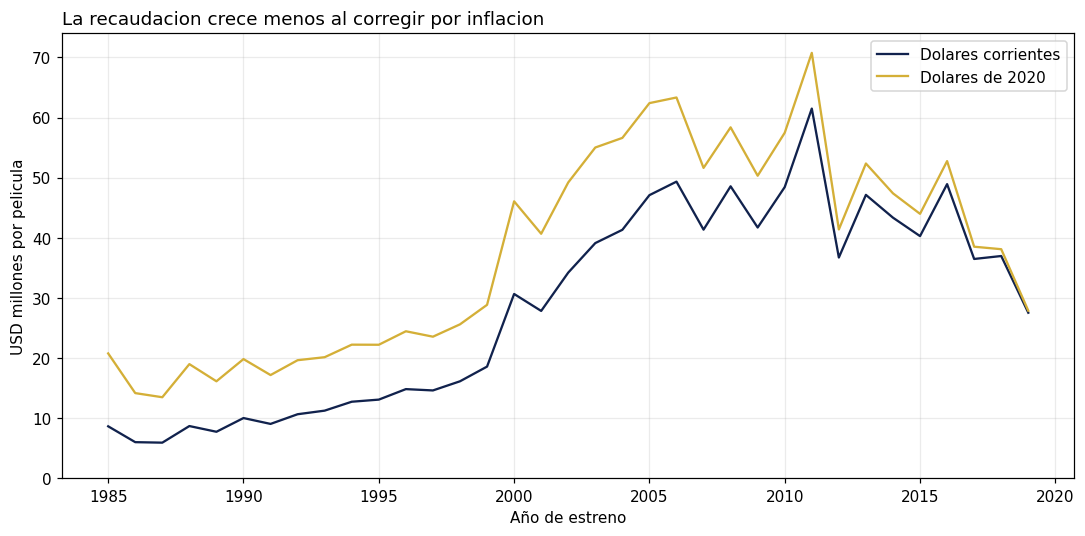

,decada,peliculas,nominal_mediana_millones,real_mediana_millones
0,1990,2000,12.87,22.13
1,2000,2000,40.41,53.42
2,2010,2000,41.67,45.79


,anio_estreno,peliculas,con_recaudacion,sin_recaudacion_pct
40,2020,25,15,40.0


In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

# Paleta usada en las clases: azul para la serie base y dorado para destacar.
AZUL_GRAFICO = '#11224D'
AZUL_CLARO_GRAFICO = '#6699CC'
DORADO_GRAFICO = '#D4AF37'
DECADA_COMPARACION_INICIO = 1990

evolucion = datos.groupby('anio_estreno').agg(
    peliculas=('id_pelicula','size'),
    con_recaudacion=('recaudacion_mundial_usd','count'),
    nominal_mediana=('recaudacion_mundial_usd','median'),
    real_mediana=('recaudacion_2020_usd','median')).reset_index()
evolucion['sin_recaudacion_pct'] = (
    100 * (1 - evolucion.con_recaudacion / evolucion.peliculas)).round(1)
evolucion['nominal_millones'] = evolucion.nominal_mediana / USD_POR_MILLON
evolucion['real_millones'] = evolucion.real_mediana / USD_POR_MILLON

serie_regular = evolucion.loc[evolucion.anio_estreno.between(
    ANIO_COBERTURA_REGULAR_INICIO, ANIO_COBERTURA_REGULAR_FIN)]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(serie_regular.anio_estreno, serie_regular.nominal_millones,
        label='Dolares corrientes', color=AZUL_GRAFICO)
ax.plot(serie_regular.anio_estreno, serie_regular.real_millones,
        label='Dolares de 2020', color=DORADO_GRAFICO)
ax.set_title('La recaudacion crece menos al corregir por inflacion', loc='left')
ax.set_xlabel('Año de estreno')
ax.set_ylabel('USD millones por pelicula')
ax.set_ylim(0, None)
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(carpeta_salidas / '34_grafico.png', dpi=150, bbox_inches='tight')
plt.show()

# Comparamos decadas completas para resumir la tendencia de las dos series.
decadas_completas = datos.loc[datos.anio_estreno.between(
    DECADA_COMPARACION_INICIO, ANIO_COBERTURA_REGULAR_FIN)]
resumen_decadas = decadas_completas.groupby('decada').agg(
    peliculas=('id_pelicula','size'),
    nominal_mediana=('recaudacion_mundial_usd','median'),
    real_mediana=('recaudacion_2020_usd','median')).reset_index()
resumen_decadas['nominal_mediana_millones'] = (
    resumen_decadas.nominal_mediana / USD_POR_MILLON)
resumen_decadas['real_mediana_millones'] = (
    resumen_decadas.real_mediana / USD_POR_MILLON)

print('Recaudacion mediana por decada completa, en USD millones:')
display(resumen_decadas[
    ['decada','peliculas','nominal_mediana_millones',
     'real_mediana_millones']].round(2))
print('Cobertura del ultimo año, excluido del grafico:')
display(evolucion.loc[evolucion.anio_estreno == ANIO_BASE_IPC,
                      ['anio_estreno','peliculas','con_recaudacion',
                       'sin_recaudacion_pct']])

Observamos que la recaudacion mediana aumenta tanto en dolares corrientes como ajustada por inflacion. El aumento es menor despues del ajuste.

Por lo tanto, parte del crecimiento era por inflacion, pero no todo.


## 3.2 ¿Cuanto rinde cada tipo de pelicula?


In [45]:
PRESUPUESTO_MIN_ANALISIS = 1_000_000
MIN_PELICULAS_COMPARABLES = 30

con_roi = datos.loc[datos.roi_salas_estimado.notna()].copy()
con_roi_hasta_2019 = con_roi.loc[
    con_roi.anio_estreno <= ANIO_COBERTURA_REGULAR_FIN].copy()
universo_negocio = con_roi_hasta_2019.loc[
    con_roi_hasta_2019.presupuesto_usd >= PRESUPUESTO_MIN_ANALISIS].copy()
universo_negocio['roi_pct'] = 100 * universo_negocio.roi_salas_estimado
universo_negocio['fracaso_25'] = universo_negocio.recupero_2_5x == 'No'

print('ROI disponibles:', len(con_roi))
print('Excluidas por 2020 incompleto:',
      len(con_roi) - len(con_roi_hasta_2019))
print('Excluidas por presupuesto menor a USD 1 millon:',
      len(con_roi_hasta_2019) - len(universo_negocio),
      f'({(len(con_roi_hasta_2019) - len(universo_negocio)) / len(con_roi_hasta_2019):.1%}'
      ' de los ROI hasta 2019)')
print('Universo principal:', len(universo_negocio),
      f'({len(universo_negocio) / len(datos):.1%} de la base depurada)')

resumen_genero = universo_negocio.groupby('genero').agg(
    peliculas=('id_pelicula','size'),
    roi_medio_pct=('roi_pct','mean'),
    roi_mediano_pct=('roi_pct','median')).reset_index()
resumen_genero['diferencia_pp'] = (
    resumen_genero.roi_medio_pct - resumen_genero.roi_mediano_pct)
print('ROI por genero, en porcentaje:')
display(resumen_genero.sort_values('peliculas', ascending=False).round(1))

resumen_secuela = universo_negocio.groupby('es_secuela').agg(
    peliculas=('id_pelicula','size'),
    roi_medio_pct=('roi_pct','mean'),
    roi_mediano_pct=('roi_pct','median')).reset_index()
print('ROI por franquicia, en porcentaje:')
display(resumen_secuela.round(1))

# El efecto del filtro se observa al comparar las mismas medias por genero.
media_todos = con_roi_hasta_2019.groupby(
    'genero').roi_salas_estimado.mean() * 100
media_principal = universo_negocio.groupby(
    'genero').roi_salas_estimado.mean() * 100
sensibilidad = pd.DataFrame({
    'media_con_todos_pct':media_todos,
    'media_principal_pct':media_principal
})
print('Efecto del filtro sobre algunas medias por genero:')
display(sensibilidad.loc[['Aventura','Comedia','Terror']].round(1))
universo_negocio['perdida_roi'] = universo_negocio.roi_salas_estimado < 0


ROI disponibles: 5389
Excluidas por 2020 incompleto: 8
Excluidas por presupuesto menor a USD 1 millon: 166 (3.1% de los ROI hasta 2019)
Universo principal: 5215 (68.0% de la base depurada)
ROI por genero, en porcentaje:
ROI por franquicia, en porcentaje:
Efecto del filtro sobre algunas medias por genero:


,genero,peliculas,roi_medio_pct,roi_mediano_pct,diferencia_pp
5,Comedia,1408,1.5,-41.8,43.3
0,Acción,1378,-11.6,-37.8,26.2
6,Drama,829,2.0,-51.8,53.8
10,Policial,385,-24.6,-56.5,32.0
2,Aventura,317,-7.9,-39.3,31.4
3,Biografía,307,-13.0,-50.9,37.9
1,Animación,272,28.0,-2.8,30.7
13,Terror,236,151.6,0.2,151.4
8,Fantasía,42,-16.1,-28.6,12.4
9,Misterio,17,-6.5,-34.1,27.6


,es_secuela,peliculas,roi_medio_pct,roi_mediano_pct
0,No,4653,-1.3,-44.6
1,Si,562,39.8,-1.5


,media_con_todos_pct,media_principal_pct
genero,,
Aventura,1733.2,-7.9
Comedia,717.4,1.5
Terror,2745.0,151.6


Para este analisis usamos las peliculas hasta 2019 con presupuesto y recaudacion disponibles. Dejamos afuera los presupuestos menores a USD 1 millon por las dudas de escala.

Esto tambien excluye peliculas baratas reales. Hay que tenerlo en cuenta al interpretar los resultados.


In [46]:
# Cambiamos unicamente el presupuesto de los 14 pares, sin sumar peliculas.
alternativas = peliculas_repetidas.loc[
    peliculas_repetidas.id_pelicula.between(ID_ADICIONAL_INICIO, ID_ADICIONAL_FIN),
    ['titulo', 'anio_estreno', 'presupuesto_usd']
].rename(columns={'presupuesto_usd':'presupuesto_alternativo'})
revision_duplicados = datos.merge(alternativas, on=['titulo','anio_estreno'],
                                  how='left')
revision_duplicados['presupuesto_revision'] = (
    revision_duplicados.presupuesto_alternativo.fillna(revision_duplicados.presupuesto_usd))
filtro_revision = (
    (revision_duplicados.presupuesto_revision >= PRESUPUESTO_MIN_ANALISIS)
    & (revision_duplicados.anio_estreno <= ANIO_COBERTURA_REGULAR_FIN)
    & revision_duplicados.recaudacion_mundial_usd.notna())
revision_roi = revision_duplicados.loc[filtro_revision].copy()
revision_roi['roi_revision'] = (
    PORCION_BOLETERIA_ESTUDIO * revision_roi.recaudacion_mundial_usd
    / (revision_roi.presupuesto_revision * (1 + MARKETING_SOBRE_PRESUPUESTO)) - 1)
print('Pares con presupuesto alternativo:', len(alternativas))
print('Porcentaje de la base revisado:', f'{len(alternativas) / len(datos):.2%}')
comparacion_duplicados = pd.DataFrame({
    'ROI mediano original (%)': universo_negocio.groupby('genero').roi_salas_estimado.median() * 100,
    'ROI mediano con alternativa (%)': revision_roi.groupby('genero').roi_revision.median() * 100
})
display(comparacion_duplicados.round(2))


Pares con presupuesto alternativo: 14
Porcentaje de la base revisado: 0.18%


,ROI mediano original (%),ROI mediano con alternativa (%)
genero,,
Acción,-37.84,-37.97
Animación,-2.78,-3.17
Aventura,-39.32,-39.32
Biografía,-50.92,-50.92
Ciencia ficción,-76.0,-76.0
Comedia,-41.78,-41.78
Drama,-51.81,-51.24
Familiar,48.23,48.23
Fantasía,-28.57,-28.57


Comparamos las medianas usando los presupuestos de las otras entradas duplicadas. Asi podemos ver cuanto depende el resultado de la version que elegimos. Esto no nos dice cual presupuesto es verdadero.


## Comparacion de la media y mediana por genero


Generos mostrados: 9 | minimo por genero: 30


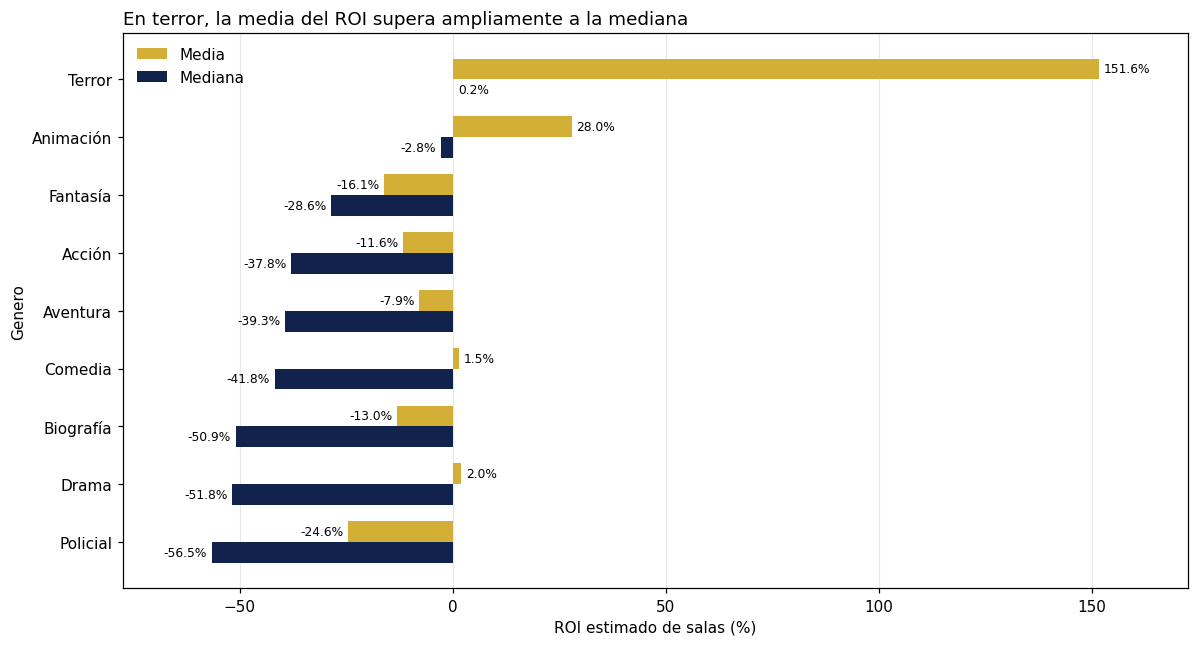

In [47]:
# Comparamos media y mediana solo en generos con suficiente muestra.
ANCHO_BARRA = 0.36
MARGEN_EJE_PCT = 0.10
generos_comparacion = resumen_genero.loc[
    resumen_genero.peliculas >= MIN_PELICULAS_COMPARABLES].sort_values(
        'roi_mediano_pct')
posiciones = np.arange(len(generos_comparacion))

fig, ax = plt.subplots(figsize=(11, 6))
barras_media = ax.barh(
    posiciones + ANCHO_BARRA / 2, generos_comparacion.roi_medio_pct,
    height=ANCHO_BARRA, color=DORADO_GRAFICO, label='Media')
barras_mediana = ax.barh(
    posiciones - ANCHO_BARRA / 2, generos_comparacion.roi_mediano_pct,
    height=ANCHO_BARRA, color=AZUL_GRAFICO, label='Mediana')

ax.set_yticks(posiciones)
ax.set_yticklabels(generos_comparacion.genero)
roi_min = min(generos_comparacion.roi_medio_pct.min(),
              generos_comparacion.roi_mediano_pct.min())
roi_max = max(generos_comparacion.roi_medio_pct.max(),
              generos_comparacion.roi_mediano_pct.max())
margen_eje = (roi_max - roi_min) * MARGEN_EJE_PCT
ax.set_xlim(roi_min - margen_eje, roi_max + margen_eje)
ax.bar_label(barras_media, fmt='%.1f%%', padding=3, fontsize=8)
ax.bar_label(barras_mediana, fmt='%.1f%%', padding=3, fontsize=8)
ax.set_title('En terror, la media del ROI supera ampliamente a la mediana',
             loc='left')
ax.set_xlabel('ROI estimado de salas (%)')
ax.set_ylabel('Genero')
ax.legend(frameon=False)
ax.grid(axis='x', alpha=0.3)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(carpeta_salidas / '38_grafico.png', dpi=150, bbox_inches='tight')
plt.show()

print('Generos mostrados:', len(generos_comparacion),
      '| minimo por genero:', MIN_PELICULAS_COMPARABLES)

En terror la media es mucho mayor que la mediana. Unas pocas peliculas muy exitosas estan subiendo el promedio.

Por eso conviene mirar las dos medidas y no concluir que todas las peliculas del genero tienen ese retorno.


In [48]:
print('Peliculas con mayor ROI en el universo principal:')
display(universo_negocio.sort_values('roi_salas_estimado', ascending=False)
        [['titulo','genero','presupuesto_usd',
          'recaudacion_mundial_usd','roi_pct']].head(8).round(1))

# Contrastamos importes pequenos: un multiplo enorme no prueba un error.
casos_a_revisar = datos.loc[datos.titulo.isin(
    ['Platoon','Paranormal Activity','The Devil Inside']),
    ['titulo','anio_estreno','presupuesto_usd',
     'recaudacion_mundial_usd','multiplo_boleteria','escala_dudosa']]
print('Casos que ayudan a distinguir errores de exitos reales:')
display(casos_a_revisar.round(1))

Peliculas con mayor ROI en el universo principal:
Casos que ayudan a distinguir errores de exitos reales:


,titulo,genero,presupuesto_usd,recaudacion_mundial_usd,roi_pct
7312,The Devil Inside,Terror,1000000.0,101758490.0,3291.9
990,Saw,Terror,1200000.0,103911669.0,2786.4
7397,E.T. the Extra-Terrestrial,Familiar,10500000.0,792910554.0,2417.2
5548,My Big Fat Greek Wedding,Comedia,5000000.0,368744044.0,2358.3
1302,The Full Monty,Comedia,3500000.0,257938649.0,2356.6
2217,Insidious,Terror,1500000.0,99557032.0,2112.4
4566,Unfriended,Terror,1000000.0,62882090.0,1996.1
217,Paranormal Activity 2,Terror,3000000.0,177512032.0,1872.4


,titulo,anio_estreno,presupuesto_usd,recaudacion_mundial_usd,multiplo_boleteria,escala_dudosa
263,Platoon,1986,6000.0,138545632.0,23090.9,True
5886,Paranormal Activity,2007,15000.0,193355800.0,12890.4,True
7312,The Devil Inside,2012,1000000.0,101758490.0,101.8,False


Observamos casos diferentes:
- Platoon tiene un presupuesto de USD 6000 en la base, pero la fuente consultada indica USD 6 millones. Esto apunta a un error de escala.
- Paranormal Activity aparece con USD 15.000, que coincide con la fuente. Es un caso real de bajo presupuesto.
- The Devil Inside tambien tiene un presupuesto chico en relacion a su recaudacion.

Por lo tanto, un retorno muy alto no alcanza para decir que hay un error.

Fuentes: [Platoon](https://time.com/3834671/platoon-oliver-stone-charlie-sheen-movie-review/), [Paranormal Activity](https://ir.paramount.com/static-files/f55db0fb-b0ca-455f-a36a-bc1f5dc03368), [The Devil Inside](https://www.the-numbers.com/movie/Devil-Inside-The).


Peliculas con puntaje IMDb y ROI: 5198
Correlacion IMDb–ROI: 0.173


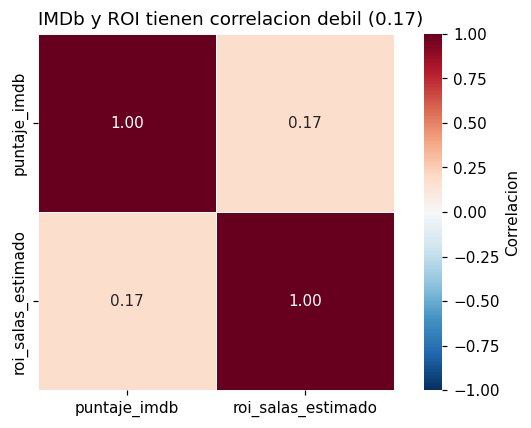

In [49]:
# Correlacion de Pearson en el mismo universo usado para comparar retornos.
variables_correlacion = ['puntaje_imdb','roi_salas_estimado']
matriz_correlacion = universo_negocio[variables_correlacion].corr()
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(matriz_correlacion, annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            linewidths=0.5, square=True,
            cbar_kws={'label':'Correlacion'}, ax=ax)
correlacion_imdb_roi = matriz_correlacion.loc[
    'puntaje_imdb','roi_salas_estimado']
ax.set_title(f'IMDb y ROI tienen correlacion debil ({correlacion_imdb_roi:.2f})',
             loc='left')
fig.tight_layout()
fig.savefig(carpeta_salidas / '42_grafico.png', dpi=150, bbox_inches='tight')
plt.show()

print('Peliculas con puntaje IMDb y ROI:',
      universo_negocio[variables_correlacion].dropna().shape[0])
print('Correlacion IMDb–ROI:', round(correlacion_imdb_roi, 3))

La relacion entre IMDb y retorno es debil. Una buena puntuacion no asegura recuperar la inversion.

Ademas, el puntaje se conoce despues del estreno. No lo podemos usar para elegir que pelicula financiar antes de hacerla.


## 3.3 ¿Donde esta el riesgo?


In [50]:
FRACCION_PEOR_DECIL = 0.10

def retorno_peor_decil(serie):
    limite = serie.quantile(FRACCION_PEOR_DECIL)
    return serie.loc[serie <= limite].mean()

def tabla_riesgo(columna):
    tabla = universo_negocio.groupby(columna).agg(
        peliculas=('id_pelicula','size'),
        roi_mediano_pct=('roi_pct','median'),
        fracaso_pct=('fracaso_25','mean'),
        perdida_roi_pct=('perdida_roi','mean'),
        roi_peor_decil_pct=('roi_pct',retorno_peor_decil)).reset_index()
    tabla['fracaso_pct'] = 100 * tabla.fracaso_pct
    tabla['perdida_roi_pct'] *= 100
    return tabla.sort_values('peliculas', ascending=False)

riesgo_genero = tabla_riesgo('genero')
riesgo_secuela = tabla_riesgo('es_secuela')
print('Riesgo por genero (ROI y fracaso en porcentaje):')
display(riesgo_genero.round(1))
print('Riesgo por franquicia (ROI y fracaso en porcentaje):')
display(riesgo_secuela.round(1))

# Aplicamos el mismo criterio de dominancia a las dos categorias de franquicia.
secuela_si = riesgo_secuela.loc[
    riesgo_secuela.es_secuela == 'Si'].iloc[0]
secuela_no = riesgo_secuela.loc[
    riesgo_secuela.es_secuela == 'No'].iloc[0]
print('Dominancia por franquicia:')
if (secuela_si.roi_mediano_pct > secuela_no.roi_mediano_pct
        and secuela_si.fracaso_pct < secuela_no.fracaso_pct):
    print('Las secuelas dominan a las no secuelas en mediana y fracaso.')
else:
    print('No hay dominancia de secuelas sobre no secuelas.')

# Dominancia compara mediana y fracaso; la propia fila no se domina a si misma.
comparables = riesgo_genero.loc[
    riesgo_genero.peliculas >= MIN_PELICULAS_COMPARABLES].reset_index(drop=True).copy()
dominador_ejemplo = []
for i in range(len(comparables)):
    actual = comparables.iloc[i]
    mejor_retorno = comparables.roi_mediano_pct >= actual.roi_mediano_pct
    menor_fracaso = comparables.fracaso_pct <= actual.fracaso_pct
    ventaja_estricta = ((comparables.roi_mediano_pct > actual.roi_mediano_pct)
                        | (comparables.fracaso_pct < actual.fracaso_pct))
    nombres = comparables.loc[mejor_retorno & menor_fracaso & ventaja_estricta,
                             'genero']
    if len(nombres) > 0:
        dominador_ejemplo.append(nombres.iloc[0])
    else:
        dominador_ejemplo.append('Ninguno')

comparables['dominador_ejemplo'] = dominador_ejemplo
print('Dominancia entre generos con al menos', MIN_PELICULAS_COMPARABLES,
      'peliculas:')
display(comparables.sort_values('roi_mediano_pct', ascending=False)
        [['genero','peliculas','roi_mediano_pct','fracaso_pct',
          'roi_peor_decil_pct','dominador_ejemplo']].round(1))
print('Generos no dominados:',
      ', '.join(list(comparables.loc[
          comparables.dominador_ejemplo == 'Ninguno', 'genero'])))

Riesgo por genero (ROI y fracaso en porcentaje):
Riesgo por franquicia (ROI y fracaso en porcentaje):
Dominancia por franquicia:
Las secuelas dominan a las no secuelas en mediana y fracaso.
Dominancia entre generos con al menos 30 peliculas:
Generos no dominados: Animación, Terror


,genero,peliculas,roi_mediano_pct,fracaso_pct,perdida_roi_pct,roi_peor_decil_pct
5,Comedia,1408,-41.8,62.9,70.3,-95.7
0,Acción,1378,-37.8,62.8,69.8,-93.2
6,Drama,829,-51.8,65.0,71.2,-98.0
10,Policial,385,-56.5,71.2,76.6,-97.3
2,Aventura,317,-39.3,61.5,69.4,-96.3
3,Biografía,307,-50.9,68.4,74.9,-95.6
1,Animación,272,-2.8,41.9,51.8,-89.1
13,Terror,236,0.2,42.8,50.0,-92.8
8,Fantasía,42,-28.6,57.1,66.7,-96.1
9,Misterio,17,-34.1,58.8,58.8,-99.3


,es_secuela,peliculas,roi_mediano_pct,fracaso_pct,perdida_roi_pct,roi_peor_decil_pct
0,No,4653,-44.6,64.5,71.3,-96.2
1,Si,562,-1.5,41.1,50.2,-86.6


,genero,peliculas,roi_mediano_pct,fracaso_pct,roi_peor_decil_pct,dominador_ejemplo
7,Terror,236,0.2,42.8,-92.8,Ninguno
6,Animación,272,-2.8,41.9,-89.1,Ninguno
8,Fantasía,42,-28.6,57.1,-96.1,Animación
1,Acción,1378,-37.8,62.8,-93.2,Animación
4,Aventura,317,-39.3,61.5,-96.3,Animación
0,Comedia,1408,-41.8,62.9,-95.7,Acción
5,Biografía,307,-50.9,68.4,-95.6,Comedia
2,Drama,829,-51.8,65.0,-98.0,Comedia
3,Policial,385,-56.5,71.2,-97.3,Comedia


Observamos el retorno mediano y la proporcion de peliculas que pierden. Tambien calculamos el retorno del peor 10% para ver cuanto se puede perder.

Un grupo domina a otro si tiene mejor retorno y menor riesgo a la vez. Esto describe lo que paso en la muestra, no asegura que se repita.


## 4.1 Evolucion nominal y real de la recaudacion


In [51]:
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

pio.templates.default = 'plotly_white'
GRIS_GRAFICO = '#BBBBBB'

figura_evolucion = go.Figure()
figura_evolucion.add_trace(go.Scatter(
    x=serie_regular.anio_estreno, y=serie_regular.nominal_millones,
    mode='lines', name='Dolares corrientes',
    line={'color':AZUL_GRAFICO,'width':2}))
figura_evolucion.add_trace(go.Scatter(
    x=serie_regular.anio_estreno, y=serie_regular.real_millones,
    mode='lines', name='Dolares de 2020',
    line={'color':DORADO_GRAFICO,'width':2}))
figura_evolucion.update_layout(
    title='La recaudacion mediana crecio menos al ajustar por inflacion',
    xaxis_title='Año de estreno',
    yaxis_title='Recaudacion mediana por pelicula (USD millones)',
    hovermode='x unified', height=460)
figura_evolucion.update_yaxes(rangemode='tozero')
figura_evolucion.write_html(carpeta_salidas / 'evolucion_interactiva.html', include_plotlyjs='cdn')
figura_evolucion.show()

print('Años mostrados:', len(serie_regular),
      '| desde', serie_regular.anio_estreno.min(),
      'hasta', serie_regular.anio_estreno.max())

Años mostrados: 35 | desde 1985 hasta 2019


El crecimiento parece mayor si no ajustamos por inflacion. En dolares de 2020 tambien aumenta la recaudacion mediana, pero menos.


## 4.2 Distribucion del ROI estimado


Peliculas mostradas: 5215
Peliculas con ROI estimado negativo: 3600 (69.0%)
ROI mayores que 300 % agrupados visualmente: 174
ROI medio y mediano (%): 3.2 y -39.9


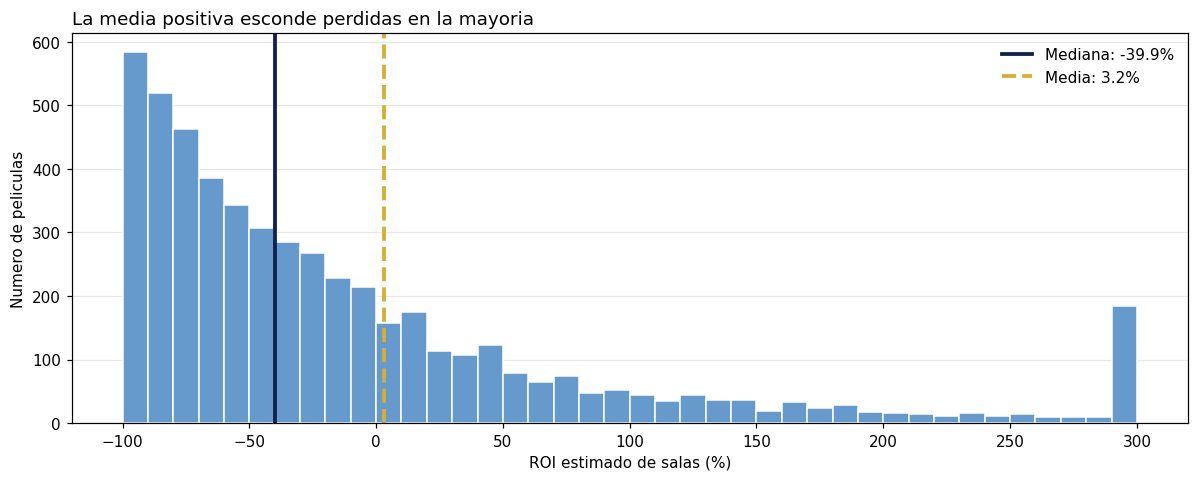

In [52]:
ROI_TOPE_VISUAL_PCT = 300
CANTIDAD_BINS_ROI = 40

roi_visual = universo_negocio[['roi_pct']].copy()
roi_visual['roi_grafico_pct'] = roi_visual.roi_pct.clip(
    upper=ROI_TOPE_VISUAL_PCT)
media_roi = roi_visual.roi_pct.mean()
mediana_roi = roi_visual.roi_pct.median()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.hist(roi_visual.roi_grafico_pct, bins=CANTIDAD_BINS_ROI,
        color=AZUL_CLARO_GRAFICO, edgecolor='white')
ax.axvline(mediana_roi, color=AZUL_GRAFICO, linewidth=2.5,
           label=f'Mediana: {mediana_roi:.1f}%')
ax.axvline(media_roi, color=DORADO_GRAFICO, linewidth=2.5,
           linestyle='--', label=f'Media: {media_roi:.1f}%')
ax.set_title('La media positiva esconde perdidas en la mayoria', loc='left')
ax.set_xlabel('ROI estimado de salas (%)')
ax.set_ylabel('Numero de peliculas')
ax.set_ylim(0, None)
ax.legend(frameon=False)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(carpeta_salidas / '52_grafico.png', dpi=150, bbox_inches='tight')
plt.show()

print('Peliculas mostradas:', len(roi_visual))
print('Peliculas con ROI estimado negativo:',
      (roi_visual.roi_pct < 0).sum(),
      f'({(roi_visual.roi_pct < 0).mean():.1%})')
print('ROI mayores que', ROI_TOPE_VISUAL_PCT, '% agrupados visualmente:',
      (roi_visual.roi_pct > ROI_TOPE_VISUAL_PCT).sum())
print('ROI medio y mediano (%):',
      round(media_roi, 1), 'y', round(mediana_roi, 1))

La media queda por encima de la mediana porque hay algunos retornos muy altos. Muchas peliculas tienen retorno negativo aunque el promedio no lo muestre.

Para ver mejor la distribucion agrupamos los retornos mayores a 300% en el ultimo tramo, solamente en el grafico.


## 4.3 Retorno mediano por genero


In [53]:
generos_grafico = comparables.sort_values('roi_mediano_pct')

figura_generos = px.bar(
    generos_grafico, x='roi_mediano_pct', y='genero',
    orientation='h', text='roi_mediano_pct',
    hover_data=['peliculas','fracaso_pct','roi_peor_decil_pct'],
    color_discrete_sequence=[AZUL_GRAFICO],
    labels={'roi_mediano_pct':'ROI mediano estimado (%)',
            'genero':'Genero',
            'peliculas':'Peliculas',
            'fracaso_pct':'Fracaso segun 2,5× (%)',
            'roi_peor_decil_pct':'ROI medio del peor decil (%)'},
    title='Terror y animacion encabezan el ROI mediano entre generos comparables')
figura_generos.update_traces(texttemplate='%{text:.1f}%',
                             textposition='outside')
figura_generos.update_layout(height=530,
                             margin={'l':90,'r':80,'t':80,'b':60})
figura_generos.write_html(carpeta_salidas / 'generos_interactivo.html', include_plotlyjs='cdn')
figura_generos.show()

print('Generos mostrados:', len(generos_grafico),
      '| minimo por genero:', MIN_PELICULAS_COMPARABLES)

Generos mostrados: 9 | minimo por genero: 30


Terror y animacion quedan entre los generos con mejor retorno mediano. Esto no significa que sean seguros: tambien tienen peliculas con perdidas. En el grafico se puede consultar cuantos casos tiene cada grupo.


## 4.4 Presupuesto frente a recaudacion


Peliculas mostradas: 5215 | excluidas por importe cero para la escala log: 0


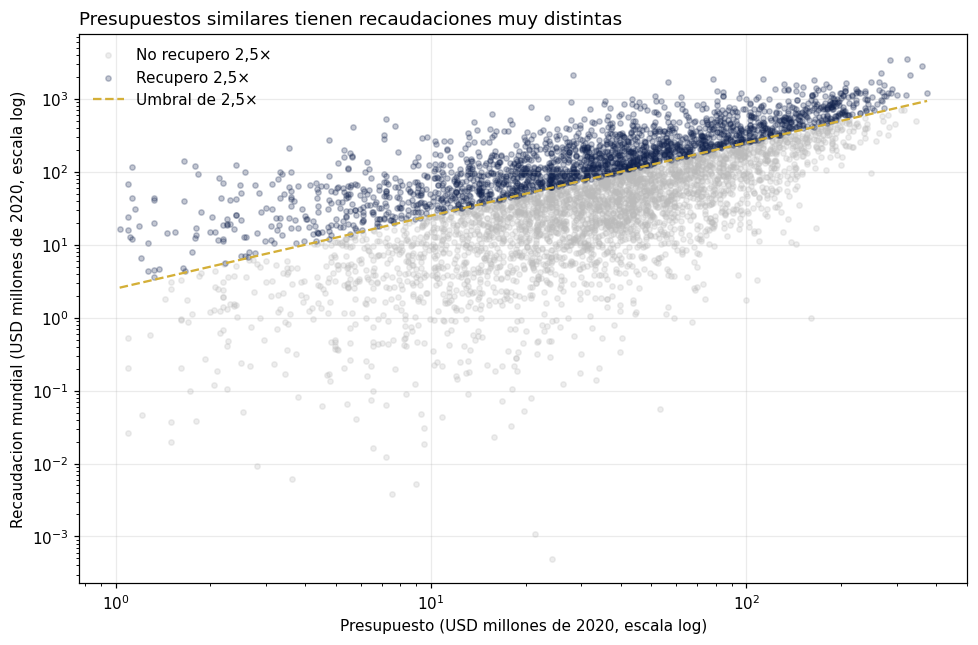

In [54]:
# La escala logaritmica requiere importes estrictamente positivos.
dispersion = universo_negocio.loc[
    (universo_negocio.presupuesto_2020_usd > 0)
    & (universo_negocio.recaudacion_2020_usd > 0)].copy()
dispersion['presupuesto_millones'] = (
    dispersion.presupuesto_2020_usd / USD_POR_MILLON)
dispersion['recaudacion_millones'] = (
    dispersion.recaudacion_2020_usd / USD_POR_MILLON)

fig, ax = plt.subplots(figsize=(9, 6))
for resultado, color, etiqueta in [
    ('No', GRIS_GRAFICO, 'No recupero 2,5×'),
    ('Si', AZUL_GRAFICO, 'Recupero 2,5×')
]:
    grupo = dispersion.loc[dispersion.recupero_2_5x == resultado]
    ax.scatter(grupo.presupuesto_millones, grupo.recaudacion_millones,
               s=12, alpha=0.25, color=color, label=etiqueta)

presupuesto_min = dispersion.presupuesto_millones.min()
presupuesto_max = dispersion.presupuesto_millones.max()
ax.plot([presupuesto_min, presupuesto_max],
        [UMBRAL_RECUPERO * presupuesto_min,
         UMBRAL_RECUPERO * presupuesto_max],
        color=DORADO_GRAFICO, linestyle='--', label='Umbral de 2,5×')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title('Presupuestos similares tienen recaudaciones muy distintas',
             loc='left')
ax.set_xlabel('Presupuesto (USD millones de 2020, escala log)')
ax.set_ylabel('Recaudacion mundial (USD millones de 2020, escala log)')
ax.legend(frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(carpeta_salidas / '58_grafico.png', dpi=150, bbox_inches='tight')
plt.show()

print('Peliculas mostradas:', len(dispersion),
      '| excluidas por importe cero para la escala log:',
      len(universo_negocio) - len(dispersion))

Peliculas con presupuestos parecidos tienen recaudaciones muy distintas. Gastar mas no asegura recuperar la inversion. La linea marca la regla de 2,5 veces el presupuesto.


# Etapa 5: propuesta de inversion

## 5.1 Definir los grupos

In [55]:
CORTES_PRESUPUESTO_M = [0, 10, 30, 70, np.inf]
NOMBRES_TRAMOS = ['Hasta 10', '10-30', '30-70', 'Mas de 70']

portafolio_base = universo_negocio.copy()
portafolio_base['presupuesto_millones'] = (
    portafolio_base.presupuesto_2020_usd / USD_POR_MILLON)
portafolio_base['tramo_presupuesto'] = pd.cut(
    portafolio_base.presupuesto_millones,
    bins=CORTES_PRESUPUESTO_M, labels=NOMBRES_TRAMOS)

# Verificamos que los tramos propuestos tengan casos suficientes.
resumen_tramos = portafolio_base.groupby(
    'tramo_presupuesto', observed=True).agg(
        peliculas=('id_pelicula','size'),
        presupuesto_mediano_m=('presupuesto_millones','median')).reset_index()
print('Peliculas y presupuesto mediano por tramo:')
display(resumen_tramos.round(1))

# Cada fila define un grupo observable; la asignacion se decide en 5.2.
grupos_elegidos = pd.DataFrame([
    {'grupo':'Animacion, mas de 70 M, secuela',
     'genero':'Animación', 'tramo':'Mas de 70', 'es_secuela':'Si'},
    {'grupo':'Accion, 30-70 M, secuela',
     'genero':'Acción', 'tramo':'30-70', 'es_secuela':'Si'},
    {'grupo':'Comedia, 30-70 M, secuela',
     'genero':'Comedia', 'tramo':'30-70', 'es_secuela':'Si'},
    {'grupo':'Terror, hasta 10 M, no secuela',
     'genero':'Terror', 'tramo':'Hasta 10', 'es_secuela':'No'}
])

filas_grupos = []
retornos_historicos = {}
for i in range(len(grupos_elegidos)):
    criterio = grupos_elegidos.iloc[i]
    historicas = portafolio_base.loc[
        (portafolio_base.genero == criterio['genero'])
        & (portafolio_base.tramo_presupuesto == criterio['tramo'])
        & (portafolio_base.es_secuela == criterio['es_secuela'])]
    retornos_historicos[criterio['grupo']] = (
        historicas.roi_salas_estimado.values)
    filas_grupos.append({
        'grupo':criterio['grupo'],
        'peliculas_historicas':len(historicas),
        'presupuesto_mediano_m':historicas.presupuesto_millones.median(),
        'roi_mediano_pct':100 * historicas.roi_salas_estimado.median(),
        'perdida_roi_pct':100 * (historicas.roi_salas_estimado < 0).mean(),
        'fracaso_pct':100 * historicas.fracaso_25.mean()
    })

resumen_grupos = pd.DataFrame(filas_grupos)
print('Cuatro grupos propuestos; presupuestos en USD millones de 2020:')
display(resumen_grupos.round(1))
print('Minimo de peliculas historicas por grupo:',
      resumen_grupos.peliculas_historicas.min())

# Comparamos los grupos intermedios con peliculas no secuela equivalentes.
comparadores = portafolio_base.loc[
    portafolio_base.genero.isin(['Acción', 'Comedia'])
    & (portafolio_base.tramo_presupuesto == '30-70')]
comparacion_secuela = comparadores.groupby(
    ['genero', 'es_secuela']).agg(
        peliculas=('id_pelicula', 'size'),
        roi_mediano_pct=('roi_salas_estimado', 'median'),
        fracaso_pct=('fracaso_25', 'mean')).reset_index()
comparacion_secuela['roi_mediano_pct'] = (
    100 * comparacion_secuela.roi_mediano_pct)
comparacion_secuela['fracaso_pct'] = (
    100 * comparacion_secuela.fracaso_pct)
print('Accion y comedia de 30–70 M: secuelas frente a no secuelas:')
display(comparacion_secuela.round(1))

Peliculas y presupuesto mediano por tramo:
Cuatro grupos propuestos; presupuestos en USD millones de 2020:
Minimo de peliculas historicas por grupo: 33
Accion y comedia de 30–70 M: secuelas frente a no secuelas:


,tramo_presupuesto,peliculas,presupuesto_mediano_m
0,Hasta 10,685,5.7
1,10-30,1612,19.3
2,30-70,1725,43.6
3,Mas de 70,1193,109.2


,grupo,peliculas_historicas,presupuesto_mediano_m,roi_mediano_pct,perdida_roi_pct,fracaso_pct
0,"Animacion, mas de 70 M, secuela",42,112.9,41.0,31.0,26.2
1,"Accion, 30-70 M, secuela",80,47.9,-8.6,53.8,46.2
2,"Comedia, 30-70 M, secuela",33,43.8,-4.0,51.5,36.4
3,"Terror, hasta 10 M, no secuela",66,5.2,44.6,40.9,37.9


,genero,es_secuela,peliculas,roi_mediano_pct,fracaso_pct
0,Acción,No,399,-51.7,71.9
1,Acción,Si,80,-8.6,46.2
2,Comedia,No,467,-47.7,66.0
3,Comedia,Si,33,-4.0,36.4


Elegimos cuatro grupos segun genero, presupuesto y si son secuelas. Los cortes de presupuesto son una decision nuestra para separar proyectos chicos, medianos y grandes.

Animacion y terror tienen medianas positivas. Accion y comedia secuela de presupuesto medio tienen medianas algo negativas, pero mejores que las no secuelas del mismo tramo. Las incluimos con una participacion limitada.


## 5.2 Distribuir los USD 500 millones

In [56]:
CAPITAL_TOTAL_M = 500
FACTOR_COSTO_TOTAL = 1 + MARKETING_SOBRE_PRESUPUESTO

asignacion = pd.DataFrame([
    {'grupo':'Animacion, mas de 70 M, secuela', 'asignacion_m':170, 'proyectos':1},
    {'grupo':'Accion, 30-70 M, secuela', 'asignacion_m':144, 'proyectos':2},
    {'grupo':'Comedia, 30-70 M, secuela', 'asignacion_m':66, 'proyectos':1},
    {'grupo':'Terror, hasta 10 M, no secuela', 'asignacion_m':120, 'proyectos':15}
])
propuesta = resumen_grupos.merge(asignacion, on='grupo')
propuesta['capital_por_proyecto_m'] = propuesta.asignacion_m / propuesta.proyectos
propuesta['produccion_por_proyecto_m'] = propuesta.capital_por_proyecto_m / FACTOR_COSTO_TOTAL
propuesta['marketing_por_proyecto_m'] = (
    propuesta.produccion_por_proyecto_m * MARKETING_SOBRE_PRESUPUESTO)
propuesta['diferencia_vs_mediana_pct'] = (
    propuesta.produccion_por_proyecto_m / propuesta.presupuesto_mediano_m - 1) * 100
propuesta['participacion_pct'] = propuesta.asignacion_m / CAPITAL_TOTAL_M * 100
print('¿La asignacion suma 500 millones?', propuesta['asignacion_m'].sum() == CAPITAL_TOTAL_M)
control_costos = (propuesta['produccion_por_proyecto_m']
                  + propuesta['marketing_por_proyecto_m']
                  - propuesta['capital_por_proyecto_m']).round(6)
print('Diferencia entre los costos y el capital por proyecto:')
display(control_costos)
display(propuesta.round(2))
print('Total asignado:', propuesta.asignacion_m.sum(), 'millones de USD')
print('Proyectos:', propuesta.proyectos.sum())


¿La asignacion suma 500 millones? True
Diferencia entre los costos y el capital por proyecto:
Total asignado: 500 millones de USD
Proyectos: 19


0    0.0
1    0.0
2    0.0
3    0.0
dtype: float64

,grupo,peliculas_historicas,presupuesto_mediano_m,roi_mediano_pct,perdida_roi_pct,fracaso_pct,asignacion_m,proyectos,capital_por_proyecto_m,produccion_por_proyecto_m,marketing_por_proyecto_m,diferencia_vs_mediana_pct,participacion_pct
0,"Animacion, mas de 70 M, secuela",42,112.92,40.99,30.95,26.19,170,1,170.0,113.33,56.67,0.37,34.0
1,"Accion, 30-70 M, secuela",80,47.88,-8.56,53.75,46.25,144,2,72.0,48.00,24.00,0.25,28.8
2,"Comedia, 30-70 M, secuela",33,43.75,-4.02,51.52,36.36,66,1,66.0,44.00,22.00,0.56,13.2
3,"Terror, hasta 10 M, no secuela",66,5.17,44.58,40.91,37.88,120,15,8.0,5.33,2.67,3.16,24.0


Los 500 millones incluyen produccion y marketing. Por eso dividimos el capital por pelicula entre 1,5 antes de compararlo con el presupuesto historico de produccion.

La propuesta suma 19 proyectos. Hay dos cosas a considerar:
- una sola pelicula de animacion recibe el 34% del dinero.
- necesitamos conseguir 15 proyectos de terror comparables en tres años.

Los montos estan en dolares de 2020. Antes de invertir habria que actualizarlos al ano correspondiente y acordar por contrato que ingresos recibe el fondo.


## 5.3 Retorno y riesgo del portafolio

In [57]:
N_SIMULACIONES = 10_000
SEMILLA_SIMULACION = 2026
retorno_central_pct = (
    (propuesta.asignacion_m * propuesta.roi_mediano_pct).sum() / CAPITAL_TOTAL_M)
print('Escenario central ponderando medianas:', f'{retorno_central_pct:.1f}%')
print('Resultado central en millones:', round(CAPITAL_TOTAL_M * retorno_central_pct / 100, 1))

generador = np.random.default_rng(SEMILLA_SIMULACION)
generador_compartido = np.random.default_rng(SEMILLA_SIMULACION + 1)
resultado_independiente_m = [0.0] * N_SIMULACIONES
resultado_compartido_m = [0.0] * N_SIMULACIONES

for i in range(len(propuesta)):
    fila = propuesta.iloc[i]
    roi_grupo = retornos_historicos[fila['grupo']]
    cantidad = int(fila['proyectos'])
    for simulacion in range(N_SIMULACIONES):
        # Sorteamos los retornos de las peliculas de este grupo.
        sorteos = generador.choice(roi_grupo, size=cantidad, replace=True)
        ganancia = fila['capital_por_proyecto_m'] * sorteos.sum()
        resultado_independiente_m[simulacion] += ganancia

    for simulacion in range(N_SIMULACIONES):
        # Aca todas las peliculas del grupo comparten el mismo resultado.
        sorteo_grupo = generador_compartido.choice(roi_grupo)
        resultado_compartido_m[simulacion] += fila['asignacion_m'] * sorteo_grupo

retornos_independientes = pd.Series(resultado_independiente_m) / CAPITAL_TOTAL_M
retornos_compartidos = pd.Series(resultado_compartido_m) / CAPITAL_TOTAL_M
filas_escenarios = []
for nombre, retornos in [('Proyectos sorteados por separado', retornos_independientes),
                         ('Resultado compartido dentro de cada grupo', retornos_compartidos)]:
    filas_escenarios.append({
        'supuesto': nombre,
        'prob_perder_capital_pct': 100 * (retornos < 0).mean(),
        'roi_decil_inferior_pct': 100 * retornos.quantile(0.10),
        'roi_mediano_pct': 100 * retornos.median()
    })
escenarios = pd.DataFrame(filas_escenarios)
display(escenarios.round(2))


Escenario central ponderando medianas: 21.6%
Resultado central en millones: 108.2


,supuesto,prob_perder_capital_pct,roi_decil_inferior_pct,roi_mediano_pct
0,Proyectos sorteados por separado,0.88,45.74,113.15
1,Resultado compartido dentro de cada grupo,23.01,-25.81,59.28


Primero ponderamos la mediana de cada grupo por el dinero que le asignamos.

Despues hacemos 10.000 sorteos de retornos historicos y contamos cuantas veces el total da negativo. Probamos tambien que las peliculas del mismo grupo compartan resultado.

La diferencia entre los escenarios muestra cuanto influye que las peliculas se muevan juntas. El percentil 10 indica el resultado por debajo del cual cae una de cada diez simulaciones, no la peor perdida posible.


## 5.4 Sensibilidad a costos y exitos extremos

In [58]:
# Reutilizamos los mismos sorteos para comparar los supuestos.
rng_sensibilidad = np.random.default_rng(2026)
resultados_sensibilidad = {}
for nombre, limite_roi, marketing in [
    ('Base: marketing 50 %', None, 0.5),
    ('ROI limitado a 1.000 %', 10, 0.5),
    ('Marketing 100 %, mismos proyectos', None, 1.0)
]:
    rng_sensibilidad = np.random.default_rng(2026)
    ingresos_m = [0.0] * N_SIMULACIONES
    costo_m = CAPITAL_TOTAL_M * (1 + marketing) / FACTOR_COSTO_TOTAL
    for i in range(len(propuesta)):
        fila = propuesta.iloc[i]
        cantidad = int(fila['proyectos'])
        for simulacion in range(N_SIMULACIONES):
            sorteos = rng_sensibilidad.choice(retornos_historicos[fila['grupo']],
                                              size=cantidad, replace=True)
            retornos = pd.Series(sorteos)
            if limite_roi is not None:
                retornos = retornos.clip(upper=limite_roi)
            ingreso = fila['capital_por_proyecto_m'] * (1 + retornos).sum()
            ingresos_m[simulacion] += ingreso
    roi_escenario = pd.Series(ingresos_m) / costo_m - 1
    resultados_sensibilidad[nombre] = {
        'capital_necesario_m': costo_m,
        'roi_mediano_pct': 100 * roi_escenario.median(),
        'prob_perder_pct': 100 * (roi_escenario < 0).mean()
    }
display(pd.DataFrame(resultados_sensibilidad).T.round(2))


,capital_necesario_m,roi_mediano_pct,prob_perder_pct
Base: marketing 50 %,500.00,113.15,0.88
ROI limitado a 1.000 %,500.00,85.45,1.32
"Marketing 100 %, mismos proyectos",666.67,59.86,6.07


Probamos que pasa si limitamos los retornos extraordinarios. Si el resultado cambia mucho, la propuesta depende de que se repitan esos exitos.

Tambien probamos marketing igual al 100% de produccion. Los mismos proyectos necesitan unos 666,7 millones, asi que no alcanzan los 500 millones. Habria que reducir la cantidad de proyectos o buscar otro financiador.


## 5.5 Donde no invertir y limitaciones

In [59]:
no_invertir = []
for genero in ['Drama', 'Policial']:
    grupo = portafolio_base.loc[
        (portafolio_base.genero == genero)
        & (portafolio_base.tramo_presupuesto == '30-70')
        & (portafolio_base.es_secuela == 'No')]
    no_invertir.append({
        'grupo':genero + ', 30-70 M, no secuela',
        'peliculas_historicas':len(grupo),
        'roi_mediano_pct':100 * grupo.roi_salas_estimado.median(),
        'fracaso_pct':100 * grupo.fracaso_25.mean()
    })

print('Grupos que evitariamos inicialmente:')
display(pd.DataFrame(no_invertir).round(1))

# Movemos los cortes para ver cuanto depende de ellos la tesis.
filas_sensibilidad_cortes = []
for corte_bajo, corte_medio, corte_alto in [(8,25,65), (10,30,70),
                                             (12,35,75)]:
    terror_bajo = portafolio_base.loc[
        (portafolio_base.genero == 'Terror')
        & (portafolio_base.es_secuela == 'No')
        & (portafolio_base.presupuesto_millones <= corte_bajo)]
    accion_media = portafolio_base.loc[
        (portafolio_base.genero == 'Acción')
        & (portafolio_base.es_secuela == 'Si')
        & (portafolio_base.presupuesto_millones > corte_medio)
        & (portafolio_base.presupuesto_millones <= corte_alto)]
    filas_sensibilidad_cortes.append({
        'cortes_millones':f'{corte_bajo}/{corte_medio}/{corte_alto}',
        'terror_n':len(terror_bajo),
        'terror_roi_mediano_pct':100 * terror_bajo.roi_salas_estimado.median(),
        'accion_n':len(accion_media),
        'accion_roi_mediano_pct':100 * accion_media.roi_salas_estimado.median()
    })

print('Sensibilidad de dos grupos a los cortes de presupuesto:')
display(pd.DataFrame(filas_sensibilidad_cortes).round(1))

Grupos que evitariamos inicialmente:
Sensibilidad de dos grupos a los cortes de presupuesto:


,grupo,peliculas_historicas,roi_mediano_pct,fracaso_pct
0,"Drama, 30-70 M, no secuela",253,-61.6,68.4
1,"Policial, 30-70 M, no secuela",121,-60.0,75.2


,cortes_millones,terror_n,terror_roi_mediano_pct,accion_n,accion_roi_mediano_pct
0,8/25/65,56,80.6,73,2.4
1,10/30/70,66,44.6,80,-8.6
2,12/35/75,80,27.8,78,-11.1


No priorizariamos drama y policial no secuela de USD 30 a 70 millones. Tienen medianas negativas y una proporcion alta de fracasos.

Limitaciones:
- faltan presupuestos y no faltan por igual en todos los grupos.
- elegimos usando resultados pasados, que pueden no repetirse.
- no conocemos los contratos ni los costos reales de marketing.
- no tenemos los ingresos de streaming.

Antes de invertir hay que revisar los presupuestos concretos y confirmar que existan proyectos comparables.


In [60]:
print('Propuesta final:')
display(propuesta.round(2))
print('Resultados de la simulacion:')
display(escenarios.round(2))


Propuesta final:
Resultados de la simulacion:


,grupo,peliculas_historicas,presupuesto_mediano_m,roi_mediano_pct,perdida_roi_pct,fracaso_pct,asignacion_m,proyectos,capital_por_proyecto_m,produccion_por_proyecto_m,marketing_por_proyecto_m,diferencia_vs_mediana_pct,participacion_pct
0,"Animacion, mas de 70 M, secuela",42,112.92,40.99,30.95,26.19,170,1,170.0,113.33,56.67,0.37,34.0
1,"Accion, 30-70 M, secuela",80,47.88,-8.56,53.75,46.25,144,2,72.0,48.00,24.00,0.25,28.8
2,"Comedia, 30-70 M, secuela",33,43.75,-4.02,51.52,36.36,66,1,66.0,44.00,22.00,0.56,13.2
3,"Terror, hasta 10 M, no secuela",66,5.17,44.58,40.91,37.88,120,15,8.0,5.33,2.67,3.16,24.0


,supuesto,prob_perder_capital_pct,roi_decil_inferior_pct,roi_mediano_pct
0,Proyectos sorteados por separado,0.88,45.74,113.15
1,Resultado compartido dentro de cada grupo,23.01,-25.81,59.28


Estas son las tablas finales para consultar los resultados y armar la presentacion.
